In [1]:
BANDS_TO_USE = ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12']
TARGET_SIZE = 120

# **TEST**

## **Global ML**

Illegal mines: gather locations and timestamps, download multispectral images with ee

In [11]:
save_dir_imgs = "./dataset/test/Global_ML/imgs/"
save_dir_masks = "./dataset/test/Global_ML/masks/"

In [12]:
import os
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
import rioxarray
import fiona

import ee
import wxee
from dotenv import load_dotenv
load_dotenv()
ee.Authenticate()
ee.Initialize(project=os.getenv("EAI_PROJECT_ID"))

import numpy as np

In [47]:
gpkg_path = './data/Global_ML/mining_area_data.gpkg'
print(f"layers:\n\t{fiona.listlayers(gpkg_path)}")

# Load the tiles table (contains the s2_tile_name)
gdf_tiles = gpd.read_file(gpkg_path, layer='tiles')
print(f"\ntiles table:\t{gdf_tiles.columns}")

# Load the validated polygons (or whichever polygon layer you intend to use)
gdf_polygons = gpd.read_file(gpkg_path, layer='test_polygons_validated') 
# Split the giant MULTIPOLYGON into individual mine polygons
gdf_polygons = gdf_polygons.explode(index_parts=False).reset_index(drop=True)
print(f"\npolygons table:\t{gdf_polygons.columns}")

# Merge them based on tile_id
gdf = gdf_polygons.merge(gdf_tiles[['tile_id', 's2_tile_id']], on='tile_id', how='left')

# apply projections
gdf_metric = gdf.to_crs(epsg=3857) 
gdf_buffered_metric = gdf_metric.copy()
gdf_buffered_metric['geometry'] = gdf_metric.geometry.centroid.buffer(600) # buffer of 600 meters around the centroid of each polygon
gdf_buffered_metric['geometry'] = gdf_buffered_metric['geometry'].envelope # cap the bounding box (makes it a perfect square)
gdf_buffered = gdf_buffered_metric.to_crs(epsg=4326)

print(f"\nMerged table:\t{gdf_buffered.columns}")

layers:
	['maus_polygons', 'tang_polygons', 'maus_bboxes', 'tang_bboxes', 'preferred_polygons', 'preferred_bboxes', 'tiles', 'test_polygons_validated']

tiles table:	Index(['tile_id', 's2_tile_id', 'source_dataset', 'preferred_dataset',
       'minetype1', 'minetype2', 'comment', 'timestamp', 'split', 'geometry'],
      dtype='object')

polygons table:	Index(['tile_id', 'geometry'], dtype='object')

Merged table:	Index(['tile_id', 'geometry', 's2_tile_id'], dtype='object')


In [ ]:
n_rois = len(gdf_buffered)

# download the mines multispectral images
for index, row in gdf_buffered.iterrows():
    minx, miny, maxx, maxy = row.geometry.bounds    # bounding box from the polygon geometry
    roi = ee.Geometry.Rectangle([minx, miny, maxx, maxy])
    
    s2_tile_id = row['s2_tile_id']
    print(f"\nProcessing ROI {index}/{n_rois-1} - Tile: {s2_tile_id}")

    try:
        # --------------- fetch the image
        parts = s2_tile_id.split('_')
        date_str = parts[2][:8]
        start_date = f"{date_str[:4]}-{date_str[4:6]}-{date_str[6:]}"
        end_date = (pd.to_datetime(start_date) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
        mgrs_tile = parts[4][1:]
        # print(f"\nProcessing ROI {index} - Tile: {s2_tile_id}\n\tDate: {start_date}, MGRS: {mgrs_tile}")
        
        s2_collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                         .filterDate(start_date, end_date)
                         .filter(ee.Filter.eq('MGRS_TILE', mgrs_tile)))
        
        if s2_collection.size().getInfo() == 0:
            print(f"Image {s2_tile_id} not found in Earth Engine.")
            continue

        s2_image = s2_collection.first().select(BANDS_TO_USE)
        
        # --------------- download the images (from the roi at the specified time interval) into the RAM
        ds = s2_image.wx.to_xarray(region=roi, scale=10, crs="EPSG:3857", progress=False)

        # --------------- convert data to numpy
        # stack bands
        data = np.stack([np.squeeze(ds[b].values) for b in BANDS_TO_USE], axis=0)    # (Channels, H, W)
        # Clean up any missing edge pixels and scale the Sentinel-2 L2A values
        data_float = data.astype(np.float32) / 10000.0
        img_array = np.nan_to_num(data_float)

        # --------------- rasterize the mask
        ds = ds.rio.write_crs("EPSG:3857") # Explicitly register CRS to prevent rioxarray crashes
        transform = ds.rio.transform()
        out_shape = (img_array.shape[1], img_array.shape[2]) # (H, W)

        # Burn the original unbuffered polygon into the mask
        original_polygon = gdf_metric.loc[index].geometry
        mask_array = rasterize(
            [(original_polygon, 1)], # Label the polygon area as 1
            out_shape=out_shape,
            transform=transform,
            fill=0, # Background is 0
            dtype='uint8'
        )

        # --------------- force 120x120 shape to guarantee compatibility with ben-ge-8k
        img_array = img_array[:, :TARGET_SIZE, :TARGET_SIZE]
        mask_array = mask_array[:TARGET_SIZE, :TARGET_SIZE]


        if img_array.max() == 0:
            print(f"Skipping ROI {index}: Image is empty (edge of swath).")
            continue
        if img_array.shape[1] < TARGET_SIZE or img_array.shape[2] < TARGET_SIZE:
            print(f"Skipping ROI {index}: Image is smaller than {TARGET_SIZE}x{TARGET_SIZE}.")
            continue

        # label = "anomaly" if mask_array.sum() >= 5 else "normal"
        label = "anomaly"

        np.save(os.path.join(save_dir_imgs, f"mines_img_{index}_{label}.npy"), img_array)
        np.save(os.path.join(save_dir_masks, f"mines_img_{index}_{label}_mask.npy"), mask_array)

        print(f"\tSaved ROI {index} - Image: {img_array.shape}, Mask: {mask_array.shape}")

    except Exception as e:
        print(f"Skipping ROI {index}, error: {e}")
        continue


Processing ROI 0/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 0 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 1/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 1 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 2/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 2 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 3/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 3 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 4/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 4 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 5/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 5 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 6/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 6 - Image: (12, 120, 120), Mask: (120, 120)

Processing R

### Validating

Loaded ROI 0
Image shape: (12, 120, 120), Min: 0.0136, Max: 0.5269
Mask shape: (120, 120), Unique values: [0 1]


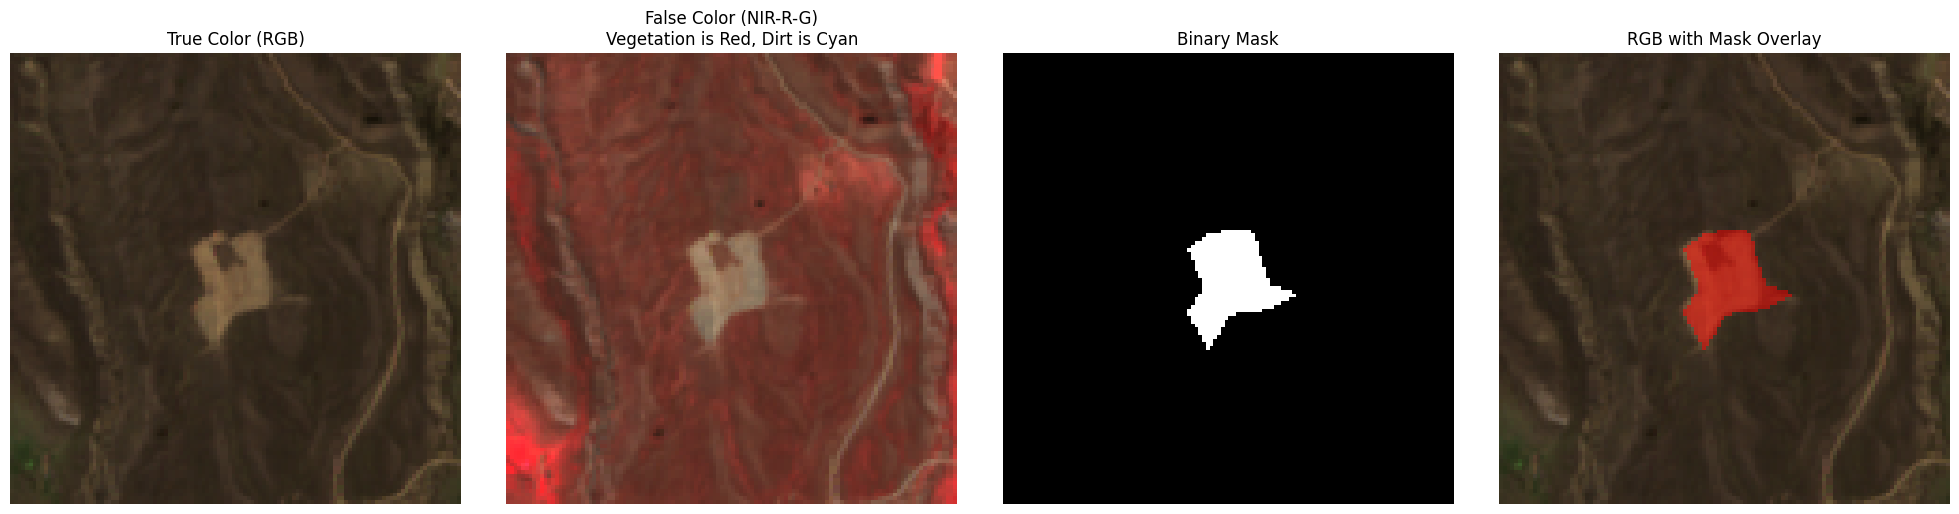

Loaded ROI 1
Image shape: (12, 120, 120), Min: 0.0194, Max: 0.3955
Mask shape: (120, 120), Unique values: [0 1]


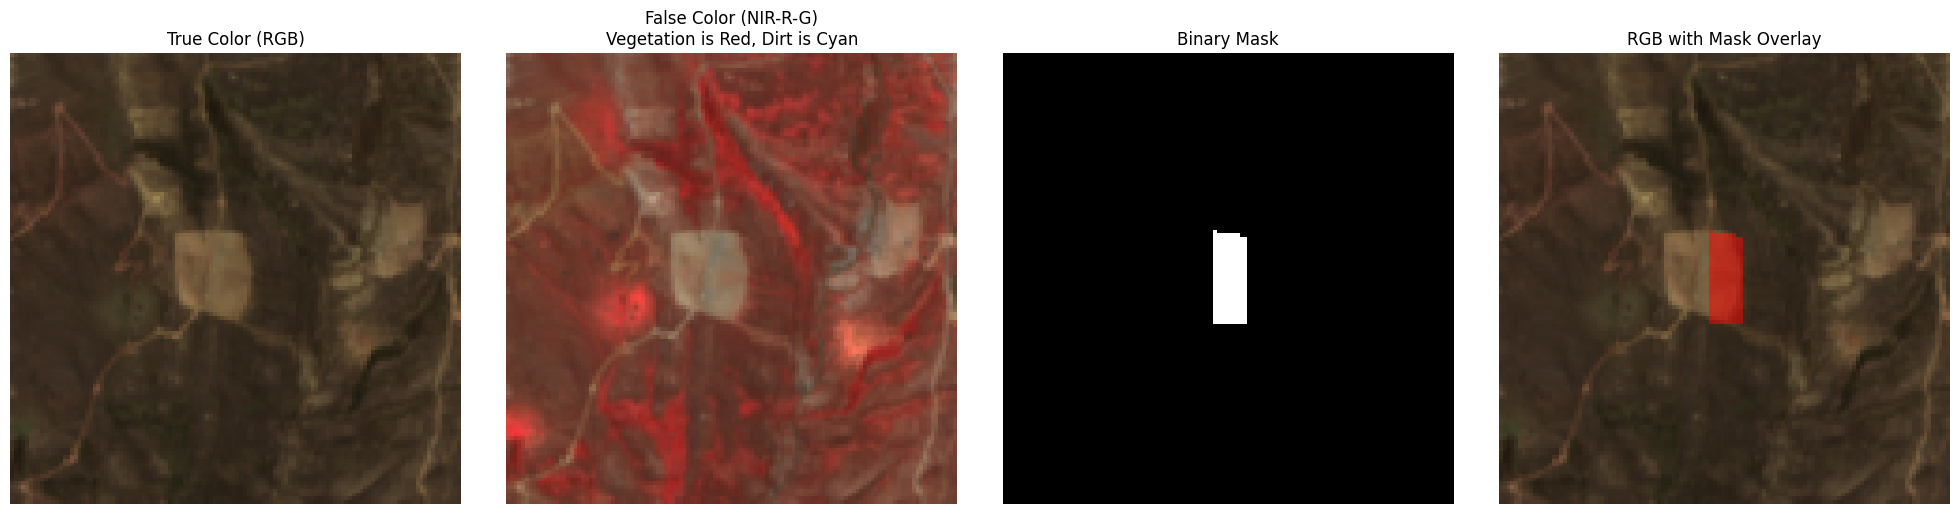

Loaded ROI 2
Image shape: (12, 120, 120), Min: 0.0000, Max: 0.3896
Mask shape: (120, 120), Unique values: [0 1]


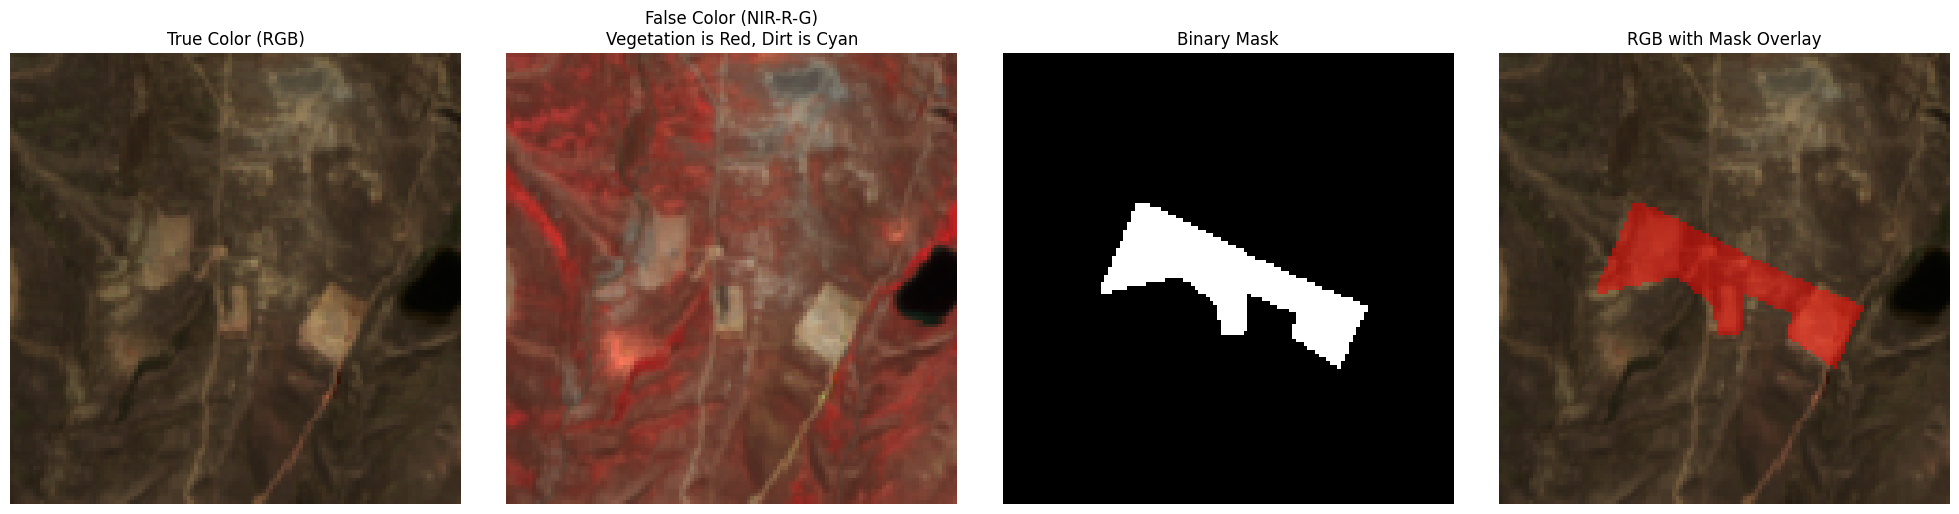

Loaded ROI 3
Image shape: (12, 120, 120), Min: 0.0001, Max: 0.4372
Mask shape: (120, 120), Unique values: [0 1]


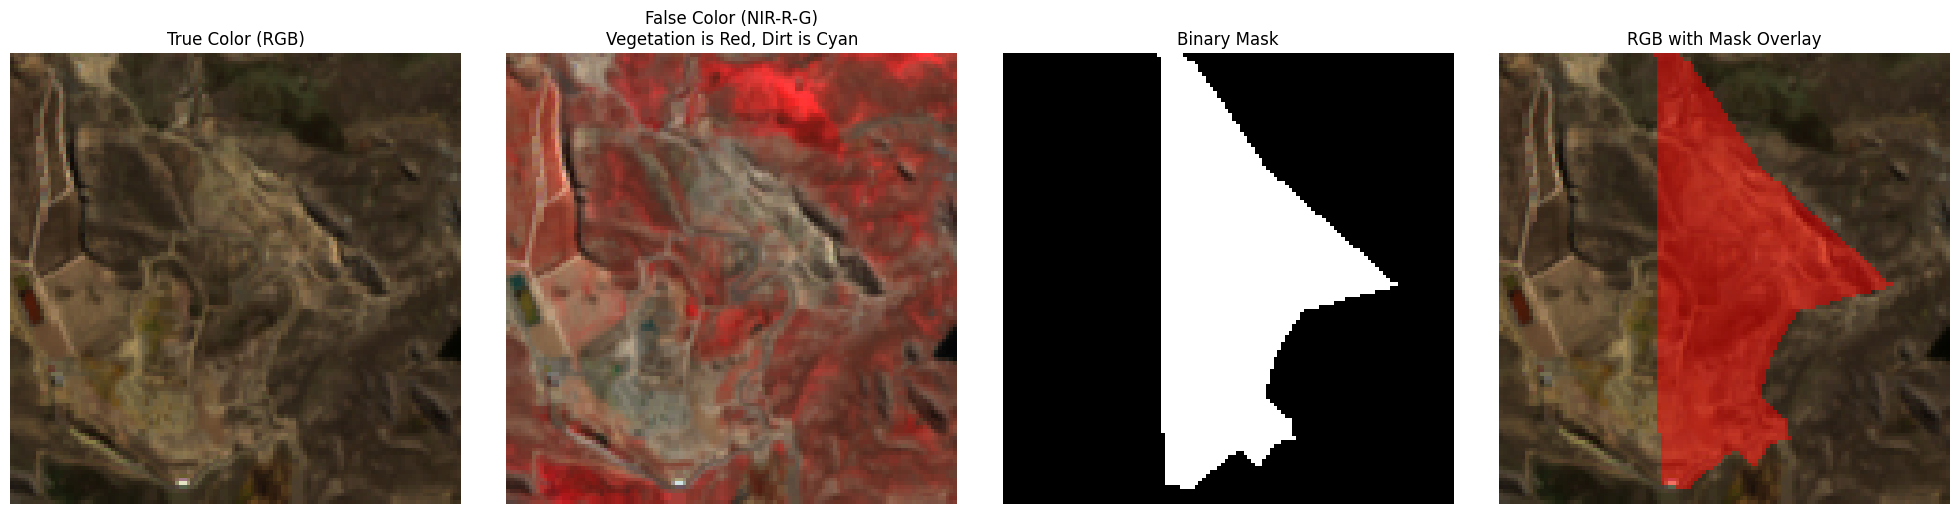

Loaded ROI 4
Image shape: (12, 120, 120), Min: 0.0001, Max: 0.4473
Mask shape: (120, 120), Unique values: [0 1]


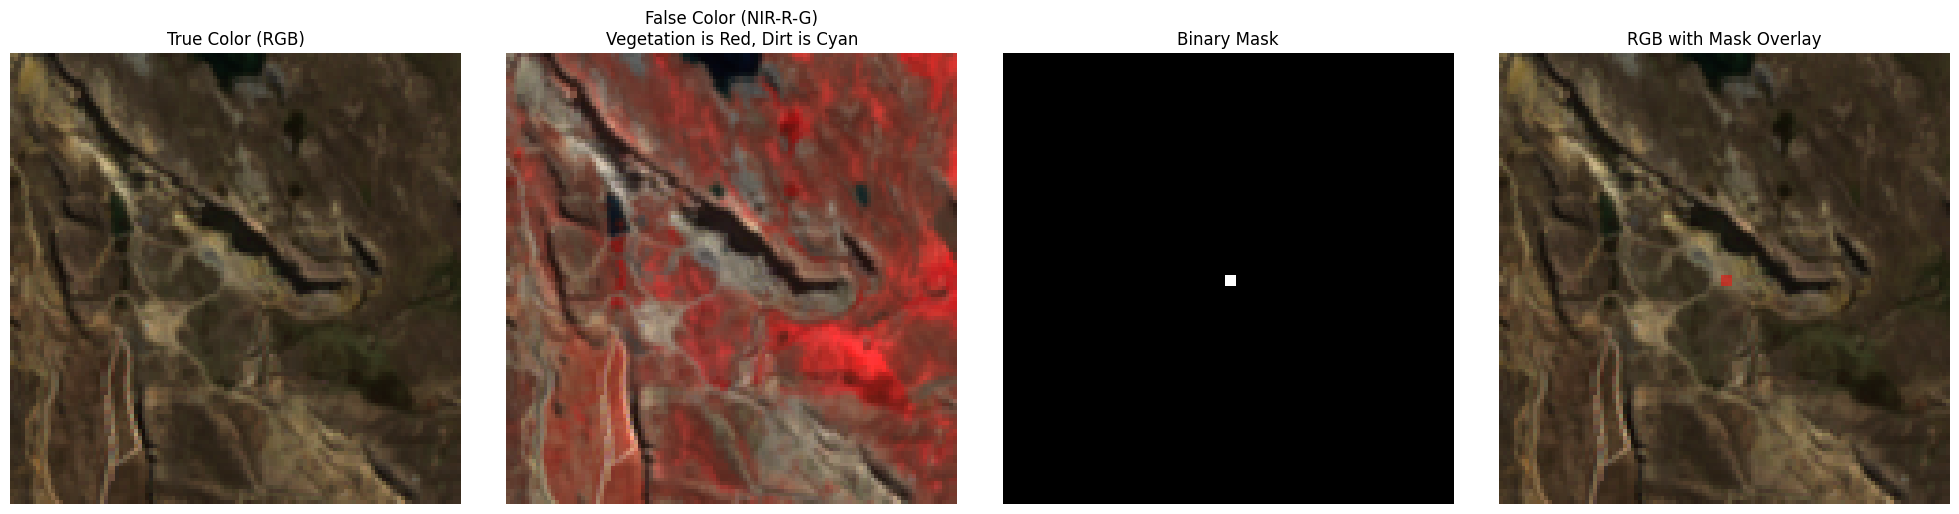

Loaded ROI 5
Image shape: (12, 120, 120), Min: 0.0012, Max: 0.8744
Mask shape: (120, 120), Unique values: [0 1]


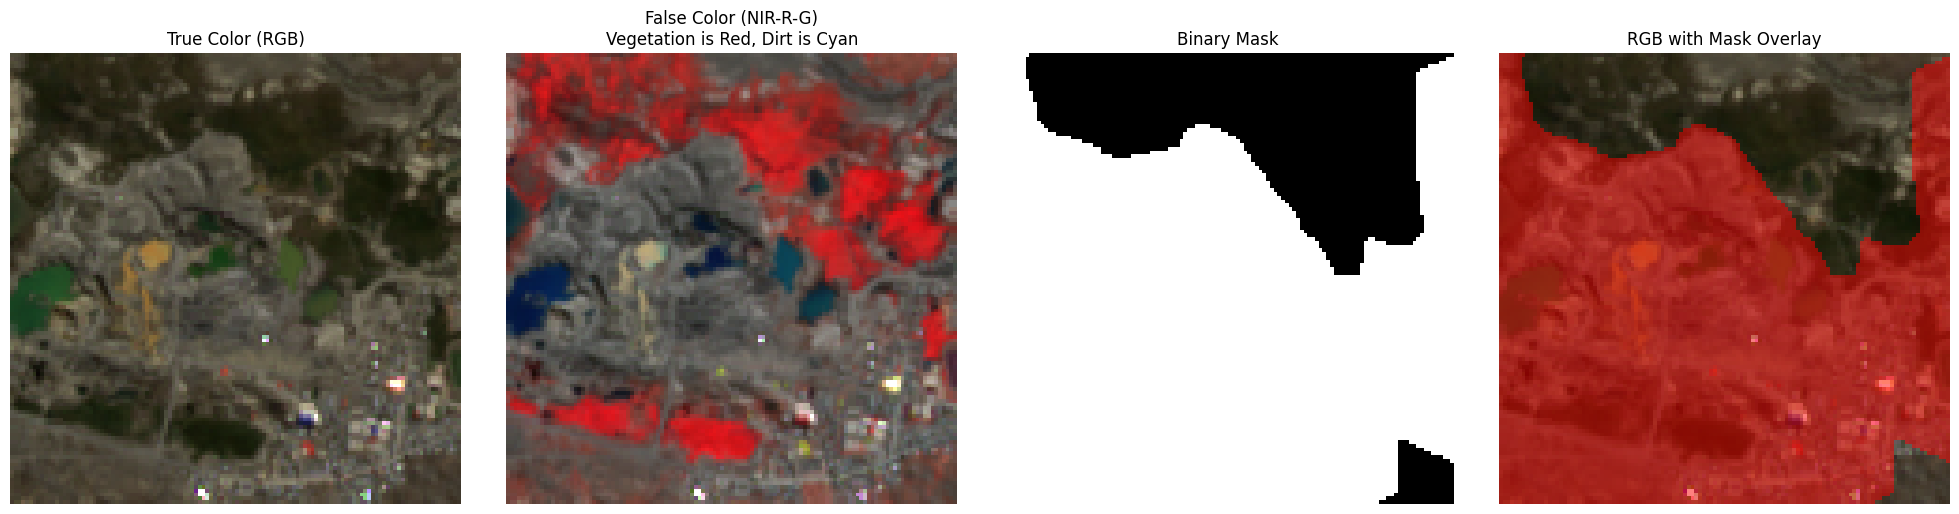

Loaded ROI 6
Image shape: (12, 120, 120), Min: 0.0000, Max: 1.6968
Mask shape: (120, 120), Unique values: [0 1]


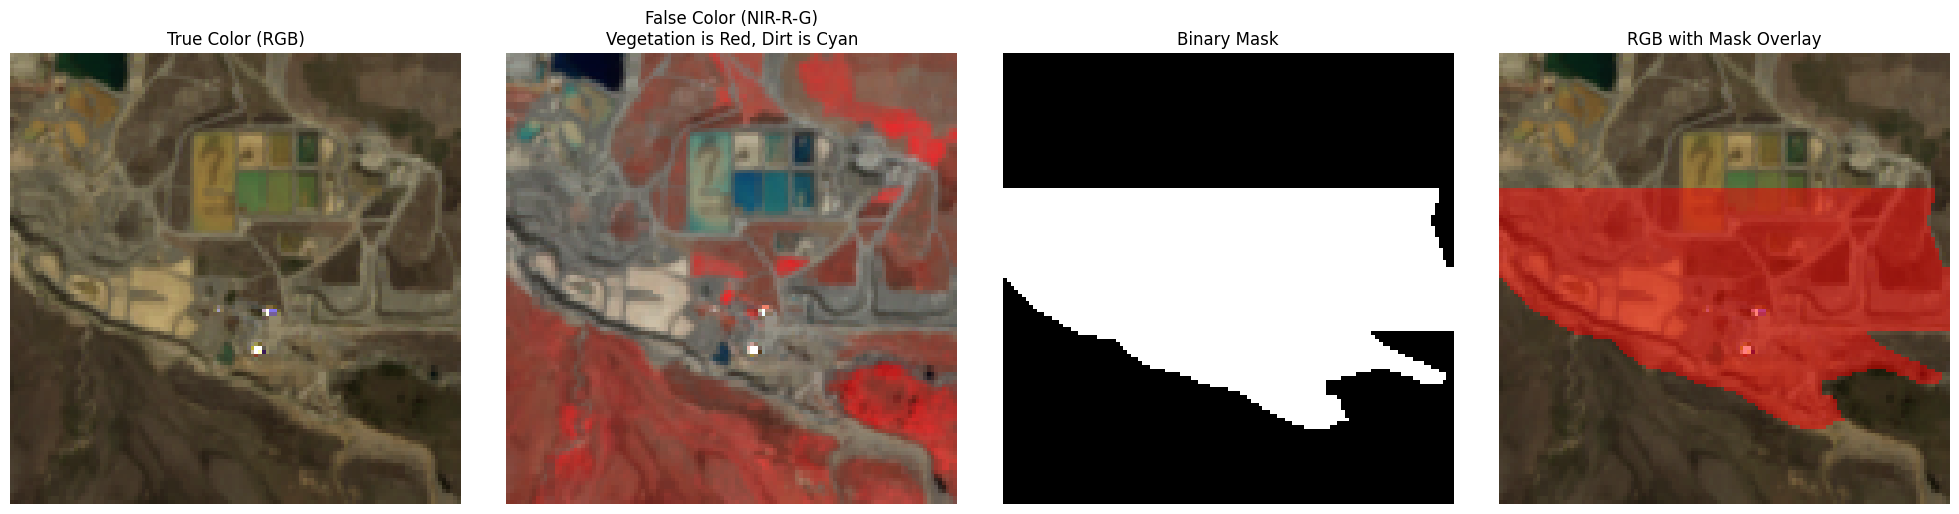

Loaded ROI 7
Image shape: (12, 120, 120), Min: 0.0055, Max: 0.4820
Mask shape: (120, 120), Unique values: [0 1]


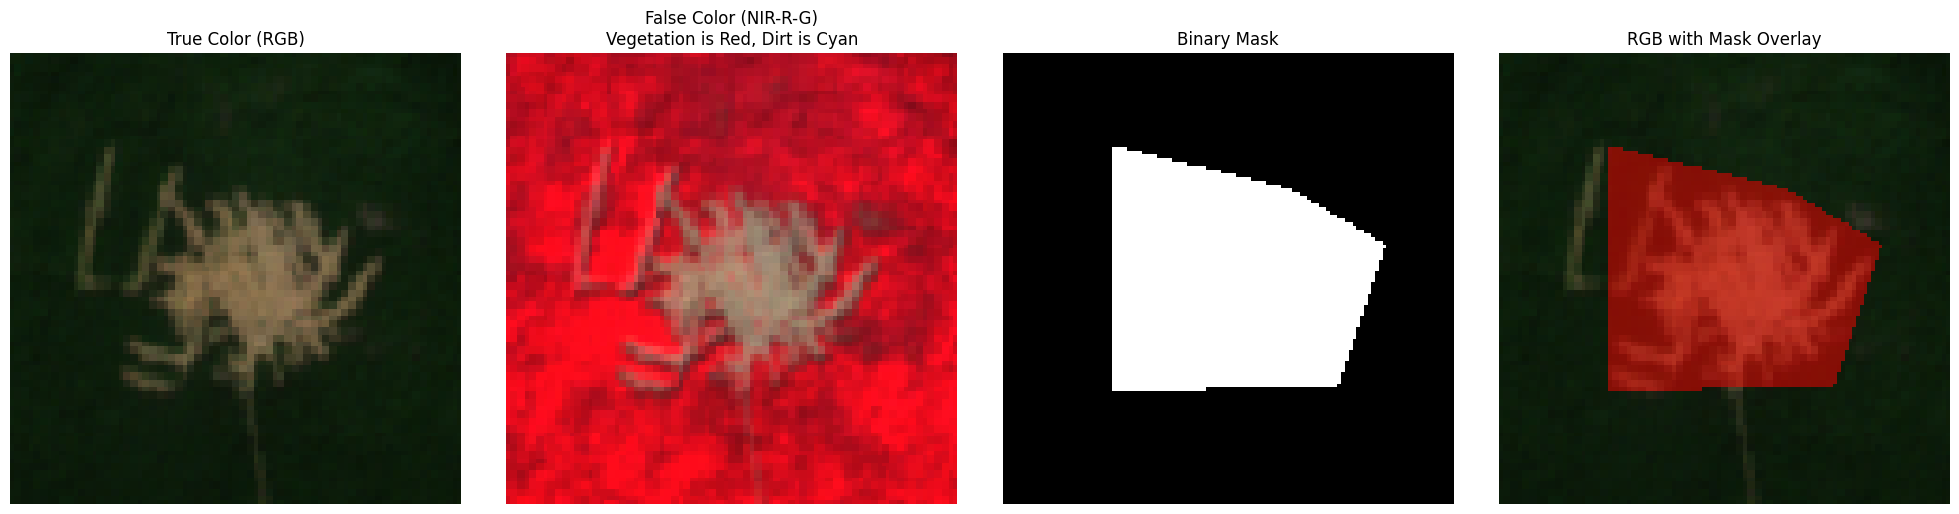

In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt

def validate_mine_patch(index, img_dir, mask_dir, prefix):
    # File paths
    img_path = os.path.join(img_dir, f"{prefix}_{index}_anomaly.npy")
    mask_path = os.path.join(mask_dir, f"{prefix}_{index}_anomaly_mask.npy")
    
    if not os.path.exists(img_path) or not os.path.exists(mask_path):
        print(f"Files for index {index} not found.")
        return

    # Load arrays
    img_array = np.load(img_path)   # Shape: (12, 120, 120)
    mask_array = np.load(mask_path) # Shape: (120, 120)
    
    print(f"Loaded ROI {index}")
    print(f"Image shape: {img_array.shape}, Min: {img_array.min():.4f}, Max: {img_array.max():.4f}")
    print(f"Mask shape: {mask_array.shape}, Unique values: {np.unique(mask_array)}")

    # Extract True Color (RGB: B4, B3, B2 -> Indices 3, 2, 1)
    rgb = img_array[[3, 2, 1], :, :].transpose(1, 2, 0)
    # Brighten the image slightly for better viewing (multiply by a factor, e.g., 2.5)
    rgb_bright = np.clip(rgb * 2.5, 0, 1)

    # Extract False Color Infrared (NIR, Red, Green: B8, B4, B3 -> Indices 7, 3, 2)
    # This makes vegetation appear bright red, and bare earth/mines appear cyan/grey
    fcc = img_array[[7, 3, 2], :, :].transpose(1, 2, 0)
    fcc_bright = np.clip(fcc * 2.5, 0, 1)

    # Setup the plot
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    # 1. True Color
    axes[0].imshow(rgb_bright)
    axes[0].set_title("True Color (RGB)")
    axes[0].axis("off")

    # 2. False Color
    axes[1].imshow(fcc_bright)
    axes[1].set_title("False Color (NIR-R-G)\nVegetation is Red, Dirt is Cyan")
    axes[1].axis("off")

    # 3. Mask Only
    axes[2].imshow(mask_array, cmap="gray")
    axes[2].set_title("Binary Mask")
    axes[2].axis("off")

    # 4. Mask Overlay on True Color
    axes[3].imshow(rgb_bright)
    # Overlay the mask using a red colormap and some transparency (alpha)
    # We mask out the '0' values so only the '1's (the mine) show up in red
    mask_overlay = np.ma.masked_where(mask_array == 0, mask_array)
    axes[3].imshow(mask_overlay, cmap="autumn", alpha=0.5)
    
    # Alternatively, draw a contour line instead of a solid fill:
    # axes[3].contour(mask_array, levels=[0.5], colors=['red'], linewidths=1.5)

    axes[3].set_title("RGB with Mask Overlay")
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()

# Test it on a few of the files you just generated
prefix = "mines_img"
img_dir = "./dataset/test/mines/imgs"
mask_dir = "./dataset/test/mines/masks/"
for i in range(8):  # Assuming indices 0, 1, 2 exist based on your log
    validate_mine_patch(i, img_dir, mask_dir, prefix)

## **hls burn scars**
Burn scars: gather locations and timestamps, download multispectral images with ee

In [20]:
save_dir_imgs = "./dataset/test/hls_burn_scars/imgs"
save_dir_masks = "./dataset/test/hls_burn_scars/masks"

In [16]:
import os
import glob
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import rasterio
import rioxarray
import numpy as np

import ee
import wxee
from dotenv import load_dotenv
load_dotenv()
ee.Authenticate()
ee.Initialize(project=os.getenv("EAI_PROJECT_ID"))

In [ ]:
# Locate all mask files in the dataset
mask_files = glob.glob('./data/hls_burn_scars/validation/*.mask.tif') 
num_files = len(mask_files)
print(f"{num_files} mask files")

for index, mask_path in enumerate(mask_files):
    # example filename: subsetted_512x512_HLS.S30.T10SEH.2018190.v1.4.mask.tif
    basename = os.path.basename(mask_path)
    parts = basename.split('.')
        
    print(f"\nProcessing ROI {index}/{num_files-1} - Tile: {parts[2]}")
    if parts[1] != 'S30':
        print(f"\tSkipping {index}: Not a Sentinel-2 (S30) patch.")
        continue

    try:
        date_str = parts[3]  # e.g., '2018190' (Year 2018, Julian Day 190)

        center_date = pd.to_datetime(date_str, format='%Y%j')
        start_date = (center_date - pd.Timedelta(days=1)).strftime('%Y-%m-%d')
        end_date = (center_date + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
        
        # Open mask using rioxarray
        mask_da = rioxarray.open_rasterio(mask_path).squeeze()
        
        # --------------- Construct the ROI (1200m x 1200m)
        # HLS patches are 15km x 15km
        # ensure the 1200x1200m crop actually contains the burn scar by finding the center of the anomaly in the mask
        y_idx, x_idx = np.where(mask_da.values == 1)    # 1 = burn scar
        if len(y_idx) == 0:
            print(f"\tSkipping {index}: No burn scar found in this mask.")
            continue

        center_y, center_x = int(np.median(y_idx)), int(np.median(x_idx))
        lon, lat = mask_da.rio.transform() * (center_x + 0.5, center_y + 0.5)   # add 0.5 to get the exact center of the pixel
        
        pt = gpd.GeoSeries([Point(lon, lat)], crs=mask_da.rio.crs)
        # Buffer by 600m, make it a square
        roi_geom = pt.buffer(600).envelope.to_crs(epsg=4326).iloc[0]   # convert to Lat/Lon for Earth Engine
        minx, miny, maxx, maxy = roi_geom.bounds
        roi = ee.Geometry.Rectangle([minx, miny, maxx, maxy])

        # --------------- Fetch the image
        s2_collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                         .filterDate(start_date, end_date)
                         .filterBounds(roi))
        
        if s2_collection.size().getInfo() == 0:
            print(f"\tImage {basename} not found in Earth Engine.")
            continue

        # Mosaic to prevent partial tiles, and restore the time property
        s2_image = (s2_collection.mosaic()
                    .select(BANDS_TO_USE)
                    .set('system:time_start', ee.Date(start_date).millis()))
        
        # Download into RAM (Resampling to 10m Sentinel-2 resolution)
        # Request the download in the native UTM projection instead of EPSG:3857
        native_crs = mask_da.rio.crs.to_string()
        ds = s2_image.wx.to_xarray(region=roi, scale=10, crs=native_crs, progress=False)

        # --------------- Convert GEE Data to Numpy
        data = np.stack([np.squeeze(ds[b].values) for b in BANDS_TO_USE], axis=0)
        data_float = data.astype(np.float32) / 10000.0
        img_array = np.nan_to_num(data_float)

        # --------------- Resample the original HLS Mask to align with the GEE image
        ds = ds.rio.write_crs(native_crs) # use native CRS of the downloaded image
        
        # Warp, resize and crop the 30m HLS mask to perfectly match the 10m grid and bounding box of the downloaded Sentinel-2 array.
        matched_mask_da = mask_da.rio.reproject_match(ds, resampling=rasterio.enums.Resampling.nearest) # Nearest neighbor interpolation guarantees the mask remains strictly 0s and 1s
        mask_array = matched_mask_da.values.astype(np.uint8)

        # --------------- Force 120x120 shape for ben-ge-8k compatibility
        img_array = img_array[:, :TARGET_SIZE, :TARGET_SIZE]
        mask_array = mask_array[:TARGET_SIZE, :TARGET_SIZE]

        if img_array.max() == 0:
            print(f"\tSkipping ROI {index}: Image is empty (edge of swath).")
            continue
        if img_array.shape[1] < TARGET_SIZE or img_array.shape[2] < TARGET_SIZE:
            print(f"\tSkipping ROI {index}: Image is smaller than {TARGET_SIZE}x{TARGET_SIZE}.")
            continue

        label = "anomaly" if mask_array.sum() > 5 else "normal"

        np.save(os.path.join(save_dir_imgs, f"burn_patch_{index}_{label}.npy"), img_array)
        np.save(os.path.join(save_dir_masks, f"burn_patch_{index}_{label}_mask.npy"), mask_array)

        print(f"\tSaved ROI {index} - Image: {img_array.shape}, Mask: {mask_array.shape}")

    except Exception as e:
        print(f"Skipping {index}, error: {e}")
        continue

264 mask files

Processing ROI 0/263 - Tile: T16SEC
	Saved ROI 0 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 1/263 - Tile: T14SQG
	Saved ROI 1 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 2/263 - Tile: T11TMF
	Saved ROI 2 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 3/263 - Tile: T10TGL
	Saved ROI 3 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 4/263 - Tile: T17SNU
	Saved ROI 4 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 5/263 - Tile: T11TLL
	Saved ROI 5 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 6/263 - Tile: T17SLT
	Saved ROI 6 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 7/263 - Tile: T12TUN
	Saved ROI 7 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 8/263 - Tile: T16SGD
	Saved ROI 8 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 9/263 - Tile: T15TVN
	Saved ROI 9 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 10/263 - Tile: T16REV
	Saved ROI 10 - Image: (12,

Fix the masks to be binary

In [3]:
import os
import glob
import numpy as np

mask_dir = "./dataset/test/burn_scars/masks"
mask_files = glob.glob(os.path.join(mask_dir, "*_mask.npy"))

fixed_count = 0
num_masks = len(mask_files)
for mask_path in mask_files:
    # Load the array
    mask_array = np.load(mask_path)
    
    # Force strict binary: Keep exactly '1' as '1', and turn everything else (0s, 255s, etc.) to '0'
    fixed_mask = np.where(mask_array == 1, 1, 0).astype(np.uint8)
    
    # Overwrite the mask
    np.save(mask_path, fixed_mask)
    fixed_count += 1

    print(f"cleaned mask {fixed_count}/{num_masks}")

print(f"Successfully cleaned and binarized {fixed_count} masks.")

cleaned mask 1/264
cleaned mask 2/264
cleaned mask 3/264
cleaned mask 4/264
cleaned mask 5/264
cleaned mask 6/264
cleaned mask 7/264
cleaned mask 8/264
cleaned mask 9/264
cleaned mask 10/264
cleaned mask 11/264
cleaned mask 12/264
cleaned mask 13/264
cleaned mask 14/264
cleaned mask 15/264
cleaned mask 16/264
cleaned mask 17/264
cleaned mask 18/264
cleaned mask 19/264
cleaned mask 20/264
cleaned mask 21/264
cleaned mask 22/264
cleaned mask 23/264
cleaned mask 24/264
cleaned mask 25/264
cleaned mask 26/264
cleaned mask 27/264
cleaned mask 28/264
cleaned mask 29/264
cleaned mask 30/264
cleaned mask 31/264
cleaned mask 32/264
cleaned mask 33/264
cleaned mask 34/264
cleaned mask 35/264
cleaned mask 36/264
cleaned mask 37/264
cleaned mask 38/264
cleaned mask 39/264
cleaned mask 40/264
cleaned mask 41/264
cleaned mask 42/264
cleaned mask 43/264
cleaned mask 44/264
cleaned mask 45/264
cleaned mask 46/264
cleaned mask 47/264
cleaned mask 48/264
cleaned mask 49/264
cleaned mask 50/264
cleaned m

### Validating

Loaded ROI 0
Image shape: (12, 120, 120), Min: 0.0177, Max: 0.4872
Mask shape: (120, 120), Unique values: [1]


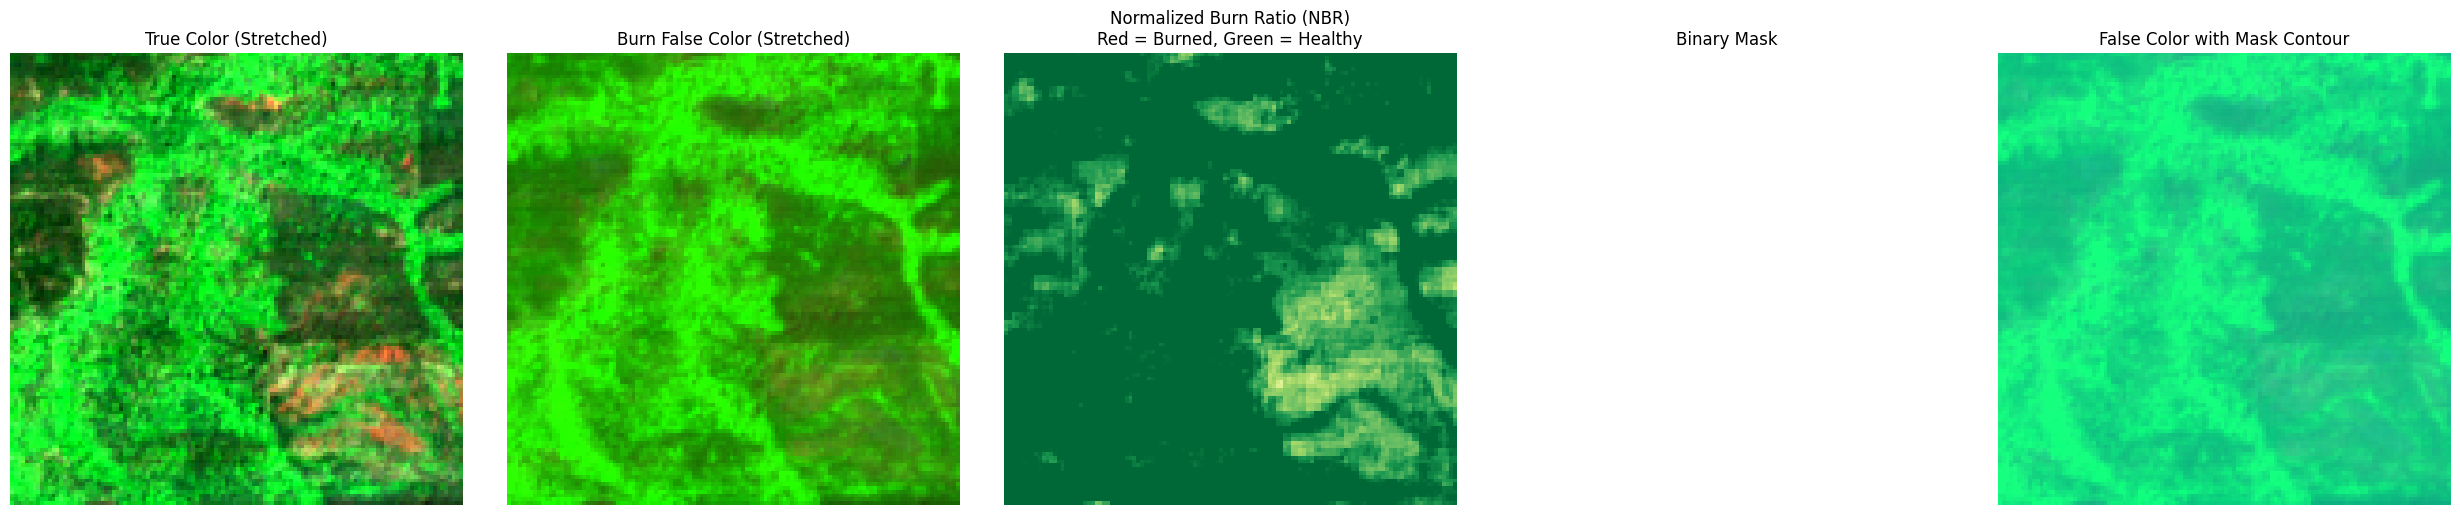

Loaded ROI 1
Image shape: (12, 120, 120), Min: 0.0226, Max: 0.3925
Mask shape: (120, 120), Unique values: [0 1]


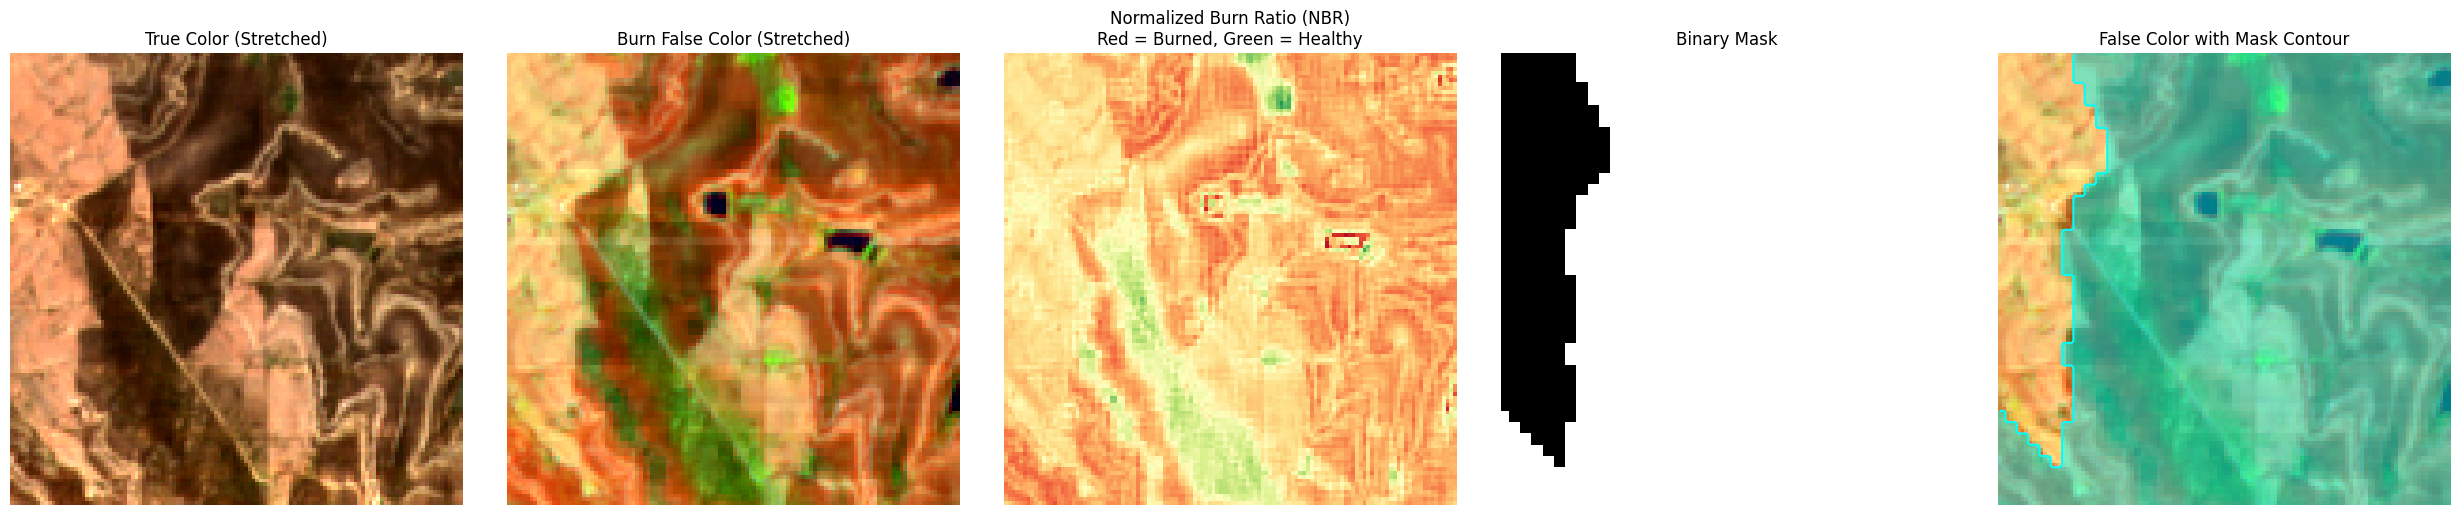

Loaded ROI 2
Image shape: (12, 120, 120), Min: 0.0361, Max: 0.3705
Mask shape: (120, 120), Unique values: [0 1]


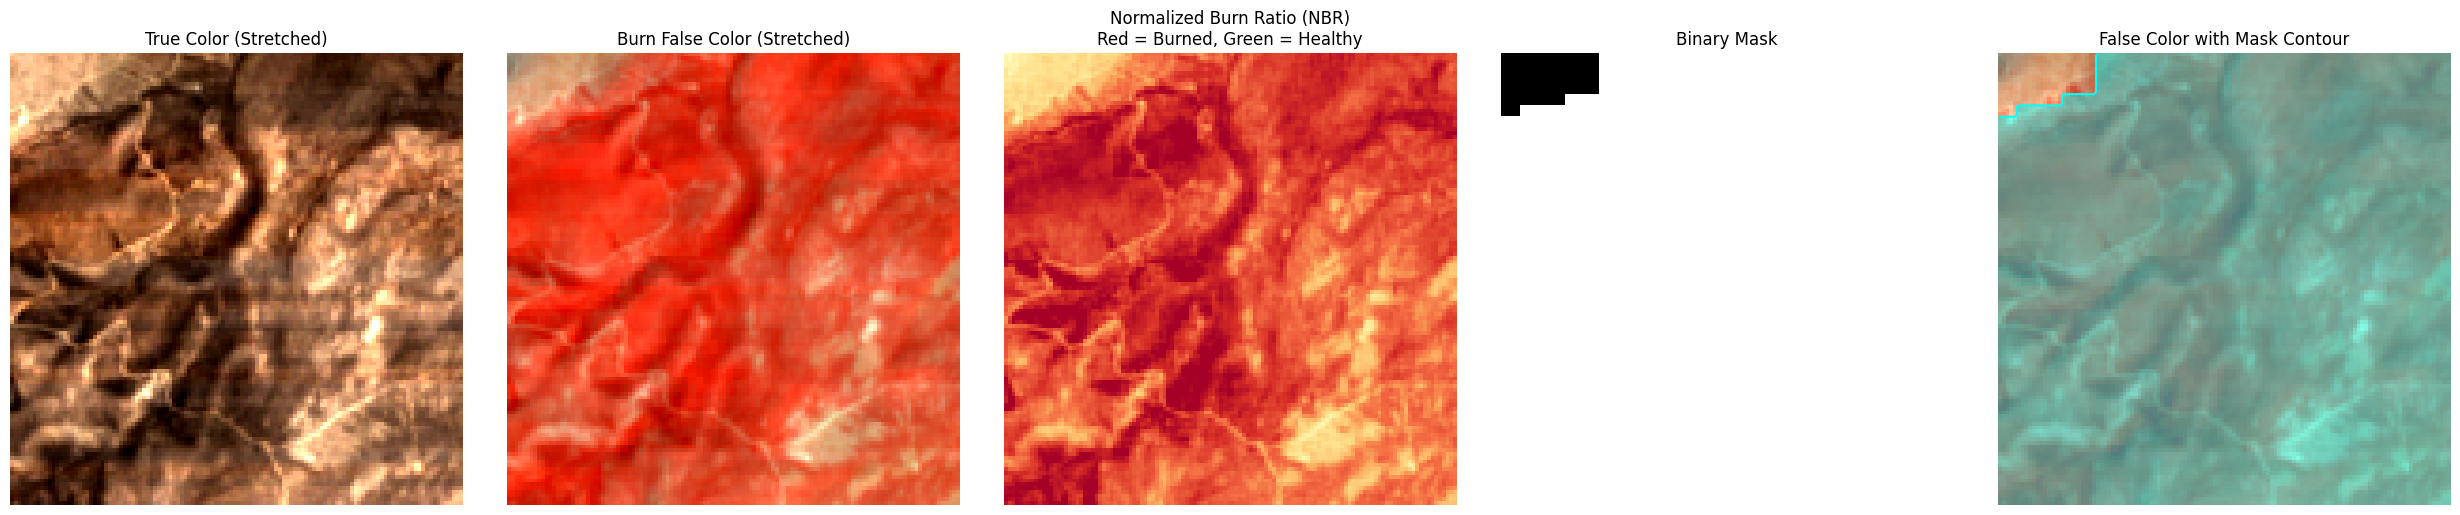

Loaded ROI 3
Image shape: (12, 120, 120), Min: 0.0567, Max: 0.2976
Mask shape: (120, 120), Unique values: [0 1]


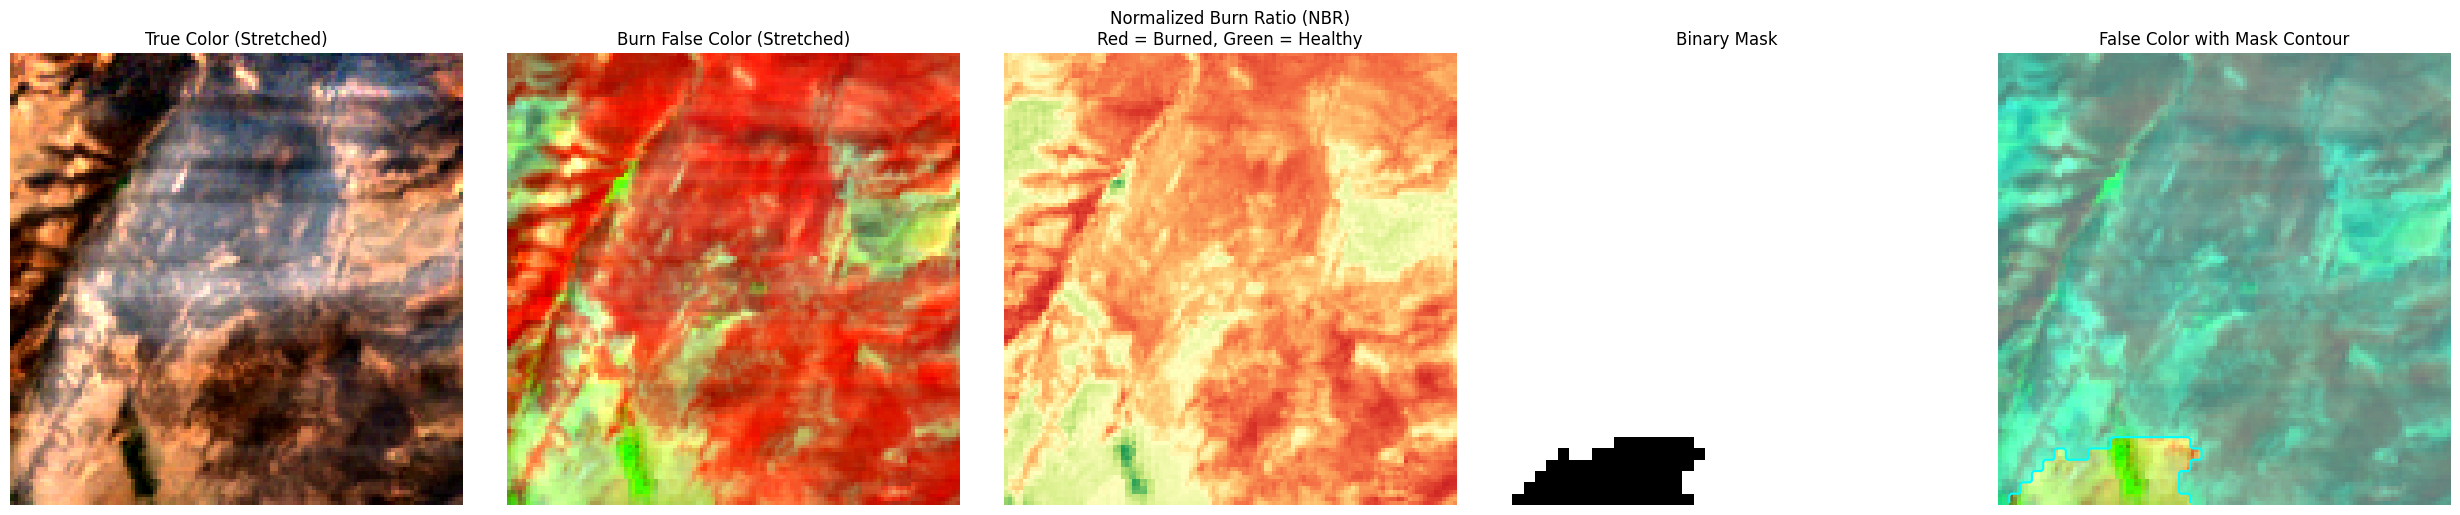

Loaded ROI 4
Image shape: (12, 120, 120), Min: 0.0200, Max: 0.4877
Mask shape: (120, 120), Unique values: [0 1]


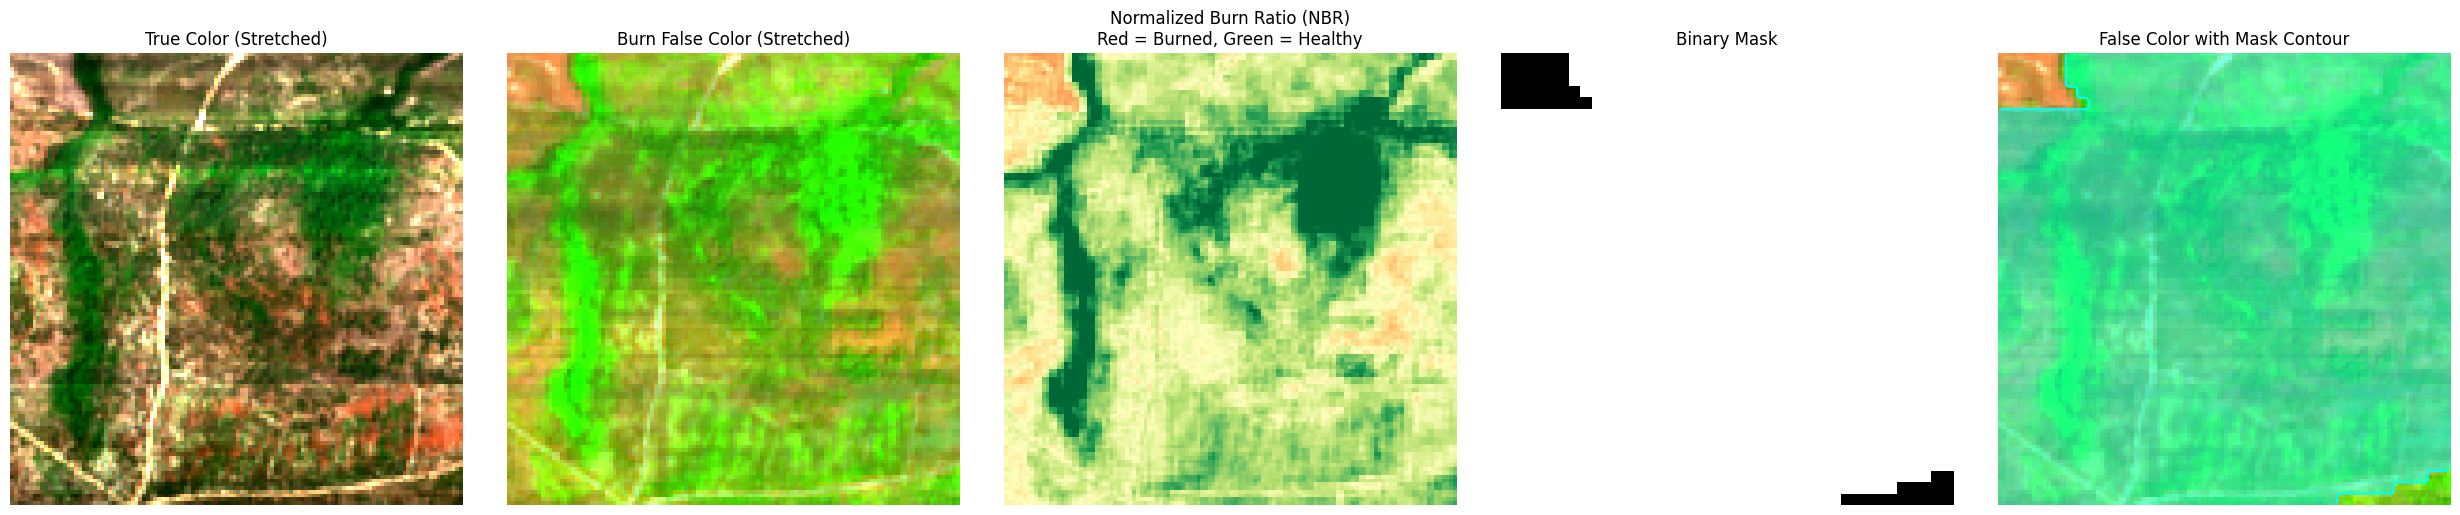

Loaded ROI 5
Image shape: (12, 120, 120), Min: 0.0157, Max: 0.3001
Mask shape: (120, 120), Unique values: [1]


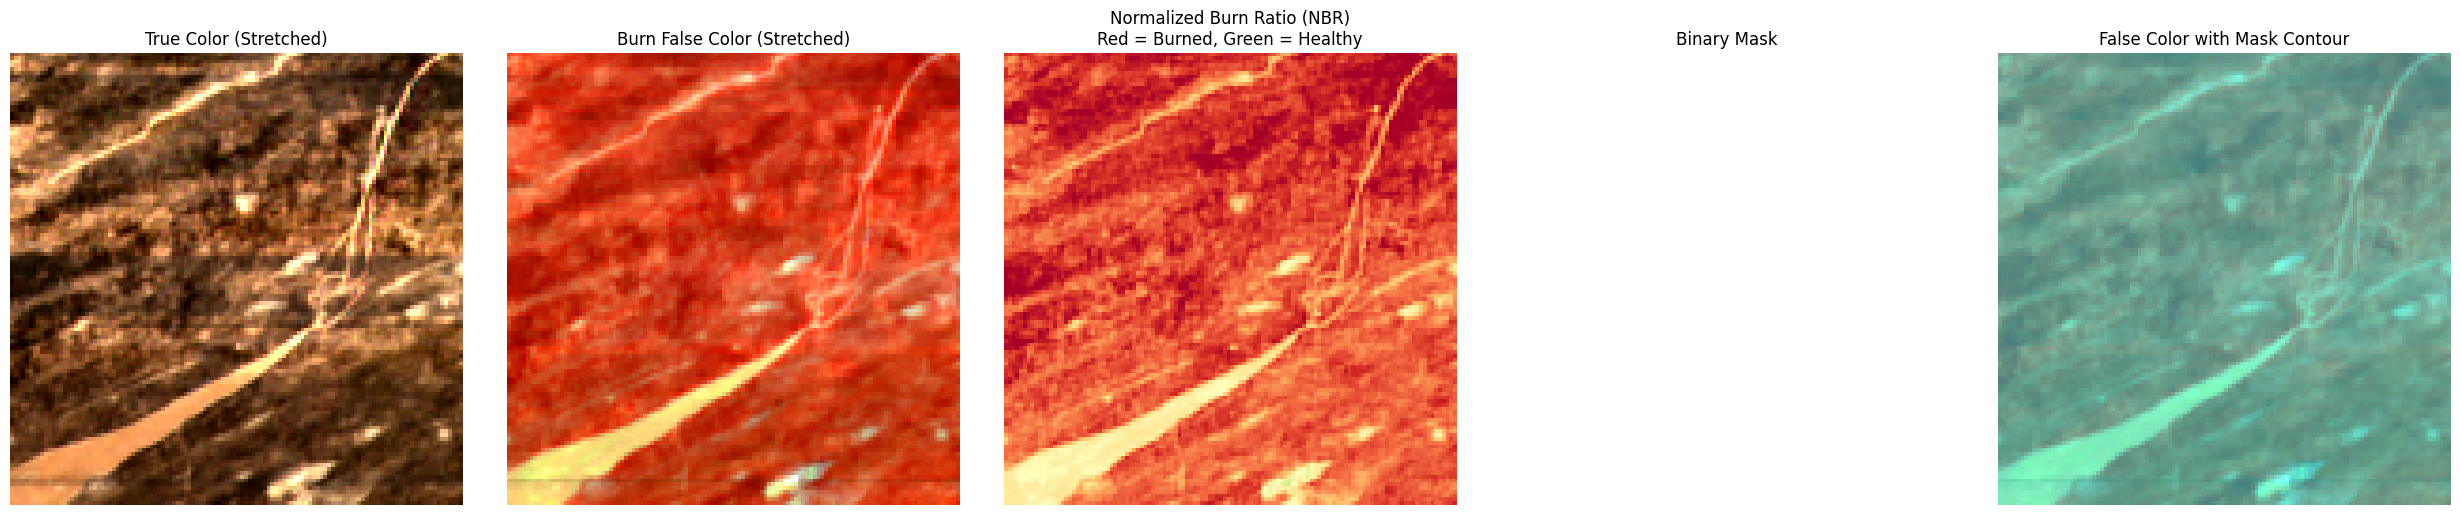

Loaded ROI 6
Image shape: (12, 120, 120), Min: 0.0093, Max: 0.4676
Mask shape: (120, 120), Unique values: [1]


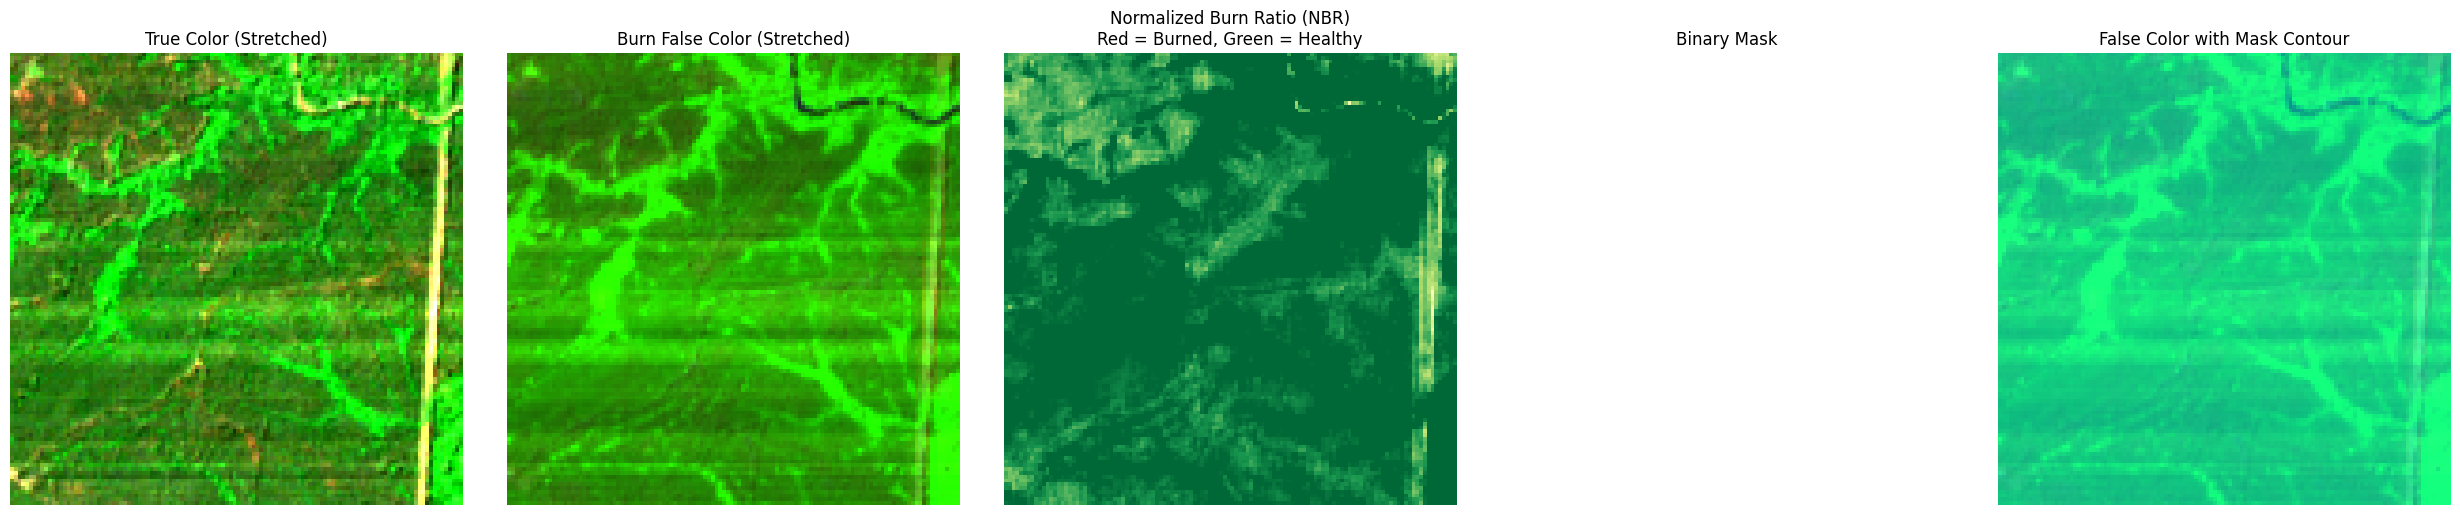

Loaded ROI 7
Image shape: (12, 120, 120), Min: 0.0259, Max: 0.3999
Mask shape: (120, 120), Unique values: [0 1]


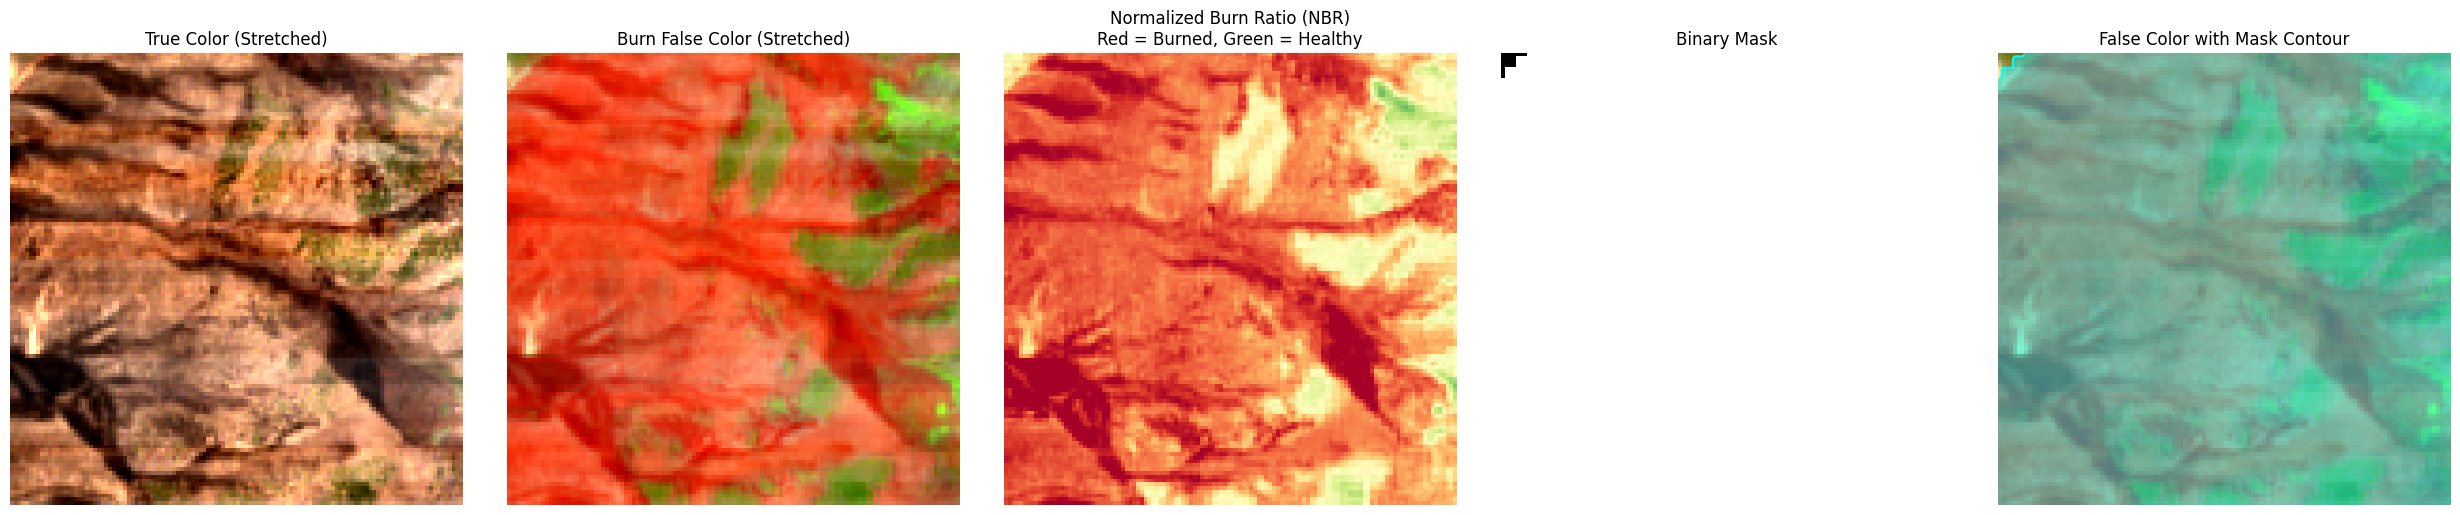

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt

# --- Helper function for robust contrast stretching ---
def robust_stretch(image_array):
    """Applies a 2nd-98th percentile stretch to each channel individually."""
    stretched = np.zeros_like(image_array)
    for i in range(image_array.shape[0]):
        band = image_array[i]
        p2, p98 = np.percentile(band, (2, 98))
        # Avoid division by zero if a band is completely flat
        if p98 - p2 == 0:
            stretched[i] = band
        else:
            stretched[i] = np.clip((band - p2) / (p98 - p2), 0, 1)
    return stretched

def validate_burn_patch(index, img_dir, mask_dir, prefix):
    # File paths
    img_path = os.path.join(img_dir, f"{prefix}_{index}_anomaly.npy")
    mask_path = os.path.join(mask_dir, f"{prefix}_{index}_anomaly_mask.npy")
    
    if not os.path.exists(img_path) or not os.path.exists(mask_path):
        print(f"Files for index {index} not found.")
        return

    # Load arrays
    img_array = np.load(img_path)   # Shape: (12, 120, 120)
    mask_array = np.load(mask_path) # Shape: (120, 120)
    
    print(f"Loaded ROI {index}")
    print(f"Image shape: {img_array.shape}, Min: {img_array.min():.4f}, Max: {img_array.max():.4f}")
    print(f"Mask shape: {mask_array.shape}, Unique values: {np.unique(mask_array)}")

    # Extract True Color (RGB: B4, B3, B2 -> Indices 3, 2, 1)
    rgb = img_array[[3, 2, 1], :, :].transpose(1, 2, 0)
    # # Brighten the image slightly for better viewing (multiply by a factor, e.g., 2.5)
    # rgb_bright = np.clip(rgb * 2.5, 0, 1)
    rgb_stretched = robust_stretch(rgb)

    # Extract Burn-Specific False Color (SWIR2, NIR, Red: B12, B8, B4 -> Indices 11, 7, 3)
    # Vegetation appears green, bare soil is tan/pink, and burn scars are stark dark red/brown.
    fcc = img_array[[11, 7, 3], :, :].transpose(1, 2, 0)
    # fcc_bright = np.clip(fcc * 2.5, 0, 1)
    fcc_stretched = robust_stretch(fcc)

    # Calculate Normalized Burn Ratio (NBR)
    # NBR = (NIR - SWIR2) / (NIR + SWIR2)
    nir = img_array[7, :, :]
    swir2 = img_array[11, :, :]
    nbr = (nir - swir2) / (nir + swir2 + 1e-8) # 1e-8 prevents division by zero

    # Setup the plot
    fig, axes = plt.subplots(1, 5, figsize=(25, 5))
    
    # 1. True Color
    axes[0].imshow(rgb_stretched)
    axes[0].set_title("True Color (Stretched)")
    axes[0].axis("off")

    # 2. Burn False Color
    axes[1].imshow(fcc_stretched)
    axes[1].set_title("Burn False Color (Stretched)")
    axes[1].axis("off")

    # Display NBR using a colormap where low values (burns) are visually distinct
    im = axes[2].imshow(nbr, cmap="RdYlGn", vmin=-0.5, vmax=0.5)
    axes[2].set_title("Normalized Burn Ratio (NBR)\nRed = Burned, Green = Healthy")
    axes[2].axis("off")

    # 3. Mask Only
    axes[3].imshow(mask_array, cmap="gray", vmin=0, vmax=1)
    axes[3].set_title("Binary Mask")
    axes[3].axis("off")

    # 4. Mask Overlay on False Color
    axes[4].imshow(fcc_stretched)
    mask_overlay = np.ma.masked_where(mask_array == 0, mask_array)
    axes[4].imshow(mask_overlay, cmap="cool", alpha=0.5)
    
    # Draw a contour line instead of a solid fill:
    axes[4].contour(mask_array, levels=[0.5], colors=['cyan'], linewidths=1.5)

    axes[4].set_title("False Color with Mask Contour")
    axes[4].axis("off")

    plt.tight_layout()
    plt.show()

# Test it on a few of the files you just generated
prefix = "burn_patch"
img_dir = "./dataset/test/burn_scars/imgs"
mask_dir = "./dataset/test/burn_scars/masks/"
for i in range(8):  # Assuming indices 0, 1, 2 exist based on your log
    validate_burn_patch(i, img_dir, mask_dir, prefix)

## **Sen12Landslides**

Land slides: gather locations and timestamps, download multispectral images with ee

In [4]:
save_dir_imgs = "./dataset/test/landslides/imgs"
save_dir_masks = "./dataset/test/landslides/masks"

In [6]:
import os
import glob
import pandas as pd
import geopandas as gpd
from shapely.geometry import box
import xarray as xr
import rasterio
import rioxarray
import numpy as np

import ee
import wxee
from dotenv import load_dotenv
load_dotenv()
ee.Authenticate()
ee.Initialize(project=os.getenv("EAI_PROJECT_ID"))

In [7]:
# Locate all .nc files dynamically across all subfolders
nc_files = glob.glob('./data/Sen12Landslides/s2/**/*.nc', recursive=True)
print(f"{len(nc_files)} NetCDF files found.")

num_files = len(nc_files)
for index, nc_path in enumerate(nc_files):
    print(f"\nProcessing ROI {index}/{num_files-1} - File: {os.path.basename(nc_path)}")

    try:
        # Load the NetCDF file using xarray
        ds_nc = xr.open_dataset(nc_path)
        
        # Extract the metadata attributes
        native_crs = ds_nc.attrs['crs']  # e.g., 'EPSG:32632'
        event_date_str = ds_nc.attrs.get('event_date')
        
        if not event_date_str:
            print(f"\tSkipping {index}: No event date found in attributes (no landslide).")
            continue
            
        # Parse the date
        event_date = pd.to_datetime(event_date_str)
        
        # Search for an image starting right after the landslide.
        # We give GEE a 30-day window to find a cloud-free image after the event.
        start_date = event_date.strftime('%Y-%m-%d')
        end_date = (event_date + pd.Timedelta(days=30)).strftime('%Y-%m-%d')

        # Register CRS so rioxarray can extract the bounding box
        ds_nc.rio.write_crs(native_crs, inplace=True)
        
        # Get bounds in the native UTM projection, convert to EPSG:4326 for GEE
        minx, miny, maxx, maxy = ds_nc.rio.bounds()
        geom = gpd.GeoSeries([box(minx, miny, maxx, maxy)], crs=native_crs)
        geom_4326 = geom.to_crs(epsg=4326).iloc[0]
        
        ee_minx, ee_miny, ee_maxx, ee_maxy = geom_4326.bounds
        roi = ee.Geometry.Rectangle([ee_minx, ee_miny, ee_maxx, ee_maxy])

        # --------------- Fetch the image from Earth Engine
        s2_collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                         .filterDate(start_date, end_date)
                         .filterBounds(roi)
                         .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 15))
                        )
        # Landslides are almost always triggered by heavy rainfall (sky covered in clouds).
        # For this reason we search for more days and discard cloudy images (we want a cloud-free image of the landslide).
        
        if s2_collection.size().getInfo() == 0:
            print(f"\tImage {os.path.basename(nc_path)} not found in Earth Engine window.")
            continue

        # Mosaic to prevent partial tiles
        s2_image = (s2_collection.mosaic()
                    .select(BANDS_TO_USE)
                    .set('system:time_start', ee.Date(start_date).millis()))
        
        # Download into RAM using the native CRS of the NetCDF patch
        ds_gee = s2_image.wx.to_xarray(region=roi, scale=10, crs=native_crs, progress=False)

        # --------------- Convert GEE Data to Numpy
        data = np.stack([np.squeeze(ds_gee[b].values) for b in BANDS_TO_USE], axis=0)
        data_float = data.astype(np.float32) / 10000.0
        img_array = np.nan_to_num(data_float)

        # --------------- Extract and align the Mask
        # The mask has shape (time, x, y). A landslide is permanent, so taking the max 
        # across the time dimension compresses it into a single spatial footprint.
        mask_da = ds_nc['MASK'].max(dim='time').transpose('y', 'x')
        
        # Ensure rioxarray knows the coordinate system of both datasets
        ds_gee = ds_gee.rio.write_crs(native_crs)
        mask_da.rio.write_crs(native_crs, inplace=True)
        
        # Snap the mask to the exact grid of the downloaded Earth Engine image
        matched_mask_da = mask_da.rio.reproject_match(ds_gee, resampling=rasterio.enums.Resampling.nearest)
        # Strictly enforce binary values to remove nodata artifacts
        raw_mask = matched_mask_da.values
        mask_array = np.where(raw_mask == 1, 1, 0).astype(np.uint8)

        # --------------- Force 120x120 shape for ben-ge-8k compatibility
        y_idx, x_idx = np.where(mask_array == 1)
        if len(y_idx) == 0:
            print(f"\tSkipping ROI {index}: No landslide found in the mask.")
            continue
        center_y, center_x = int(np.median(y_idx)), int(np.median(x_idx))
        # Calculate boundaries for a 120x120 crop around the center
        half = TARGET_SIZE // 2
        start_y = max(0, center_y - half)
        start_x = max(0, center_x - half)
        # Adjust if the crop box hits the bottom or right edges of the array
        if start_y + TARGET_SIZE > mask_array.shape[0]:
            start_y = max(0, mask_array.shape[0] - TARGET_SIZE)
        if start_x + TARGET_SIZE > mask_array.shape[1]:
            start_x = max(0, mask_array.shape[1] - TARGET_SIZE)

        img_array = img_array[:, start_y:start_y+TARGET_SIZE, start_x:start_x+TARGET_SIZE]
        mask_array = mask_array[start_y:start_y+TARGET_SIZE, start_x:start_x+TARGET_SIZE]

        if img_array.max() == 0:
            print(f"\tSkipping ROI {index}: Image is empty.")
            continue
        if img_array.shape[1] < TARGET_SIZE or img_array.shape[2] < TARGET_SIZE:
            print(f"\tSkipping ROI {index}: Image is smaller than {TARGET_SIZE}x{TARGET_SIZE}.")
            continue

        label = "anomaly"

        np.save(os.path.join(save_dir_imgs, f"landslide_patch_{index}_{label}.npy"), img_array)
        np.save(os.path.join(save_dir_masks, f"landslide_patch_{index}_{label}_mask.npy"), mask_array)

        print(f"\tSaved ROI {index} - Image: {img_array.shape}, Mask: {mask_array.shape}")

    except Exception as e:
        print(f"Skipping {index}, error: {e}")
        continue

13628 NetCDF files found.

Processing ROI 0/13627 - File: italy_s2_6236.nc
	Saved ROI 0 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 1/13627 - File: italy_s2_6598.nc
	Saved ROI 1 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 2/13627 - File: italy_s2_6015.nc
	Saved ROI 2 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 3/13627 - File: italy_s2_654.nc
	Saved ROI 3 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 4/13627 - File: italy_s2_6722.nc
	Skipping 4: No event date found in attributes (no landslide).

Processing ROI 5/13627 - File: italy_s2_6126.nc
	Skipping 5: No event date found in attributes (no landslide).

Processing ROI 6/13627 - File: italy_s2_6099.nc
	Saved ROI 6 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 7/13627 - File: italy_s2_6212.nc
	Skipping 7: No event date found in attributes (no landslide).

Processing ROI 8/13627 - File: italy_s2_6412.nc
	Skipping 8: No event date found in attributes (no landslide).

Proces

KeyboardInterrupt: 

### Validating

Loaded ROI 108
Image shape: (12, 120, 120), Min: 0.0162, Max: 0.5794
Mask shape: (120, 120), Unique values: [0 1]


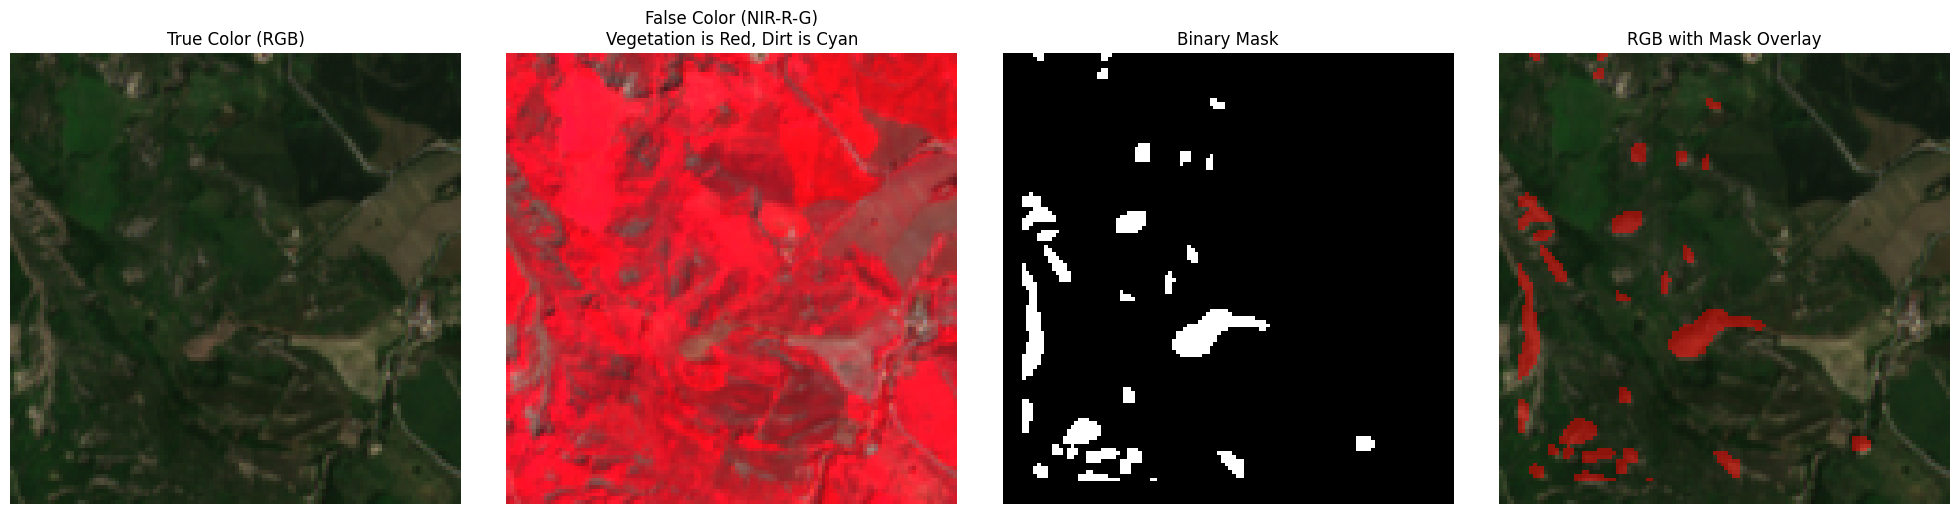

Loaded ROI 3181
Image shape: (12, 120, 120), Min: 0.0000, Max: 0.7168
Mask shape: (120, 120), Unique values: [0 1]


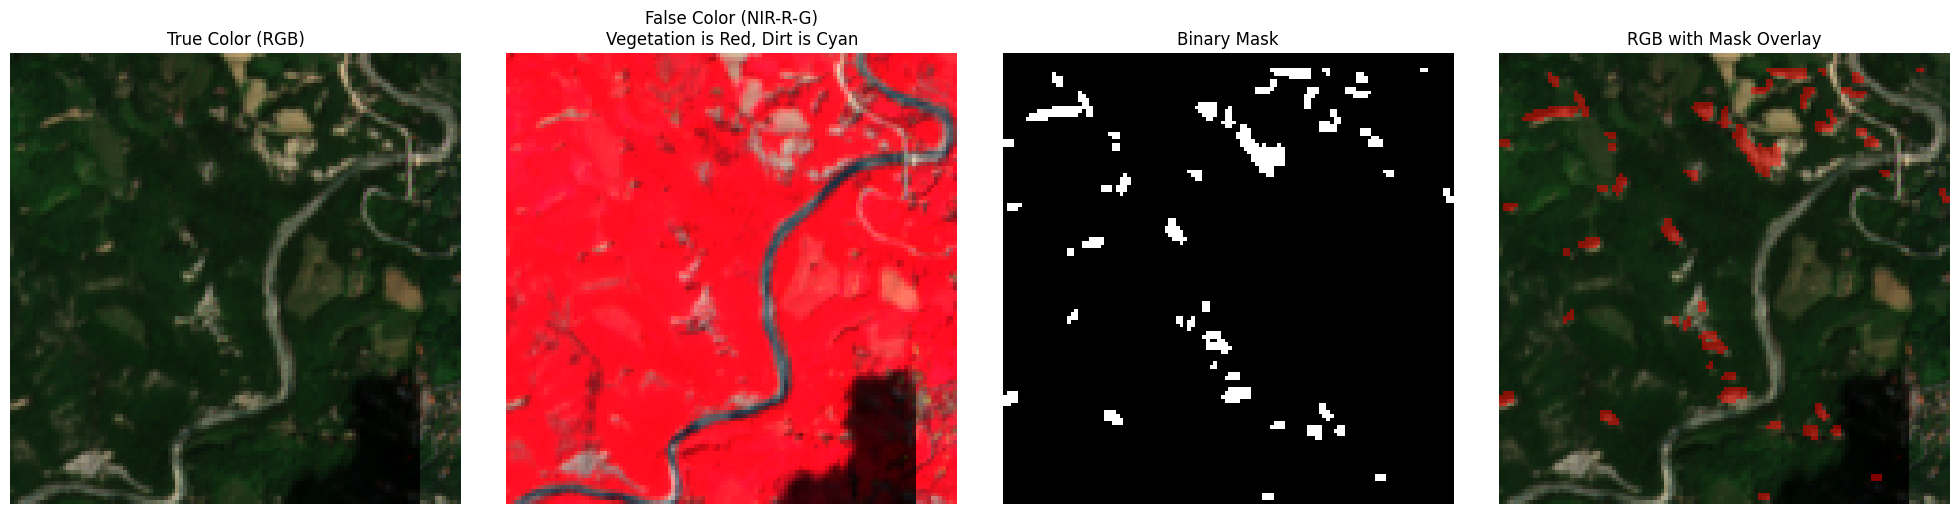

Loaded ROI 6735
Image shape: (12, 120, 120), Min: 0.0022, Max: 1.6104
Mask shape: (120, 120), Unique values: [0 1]


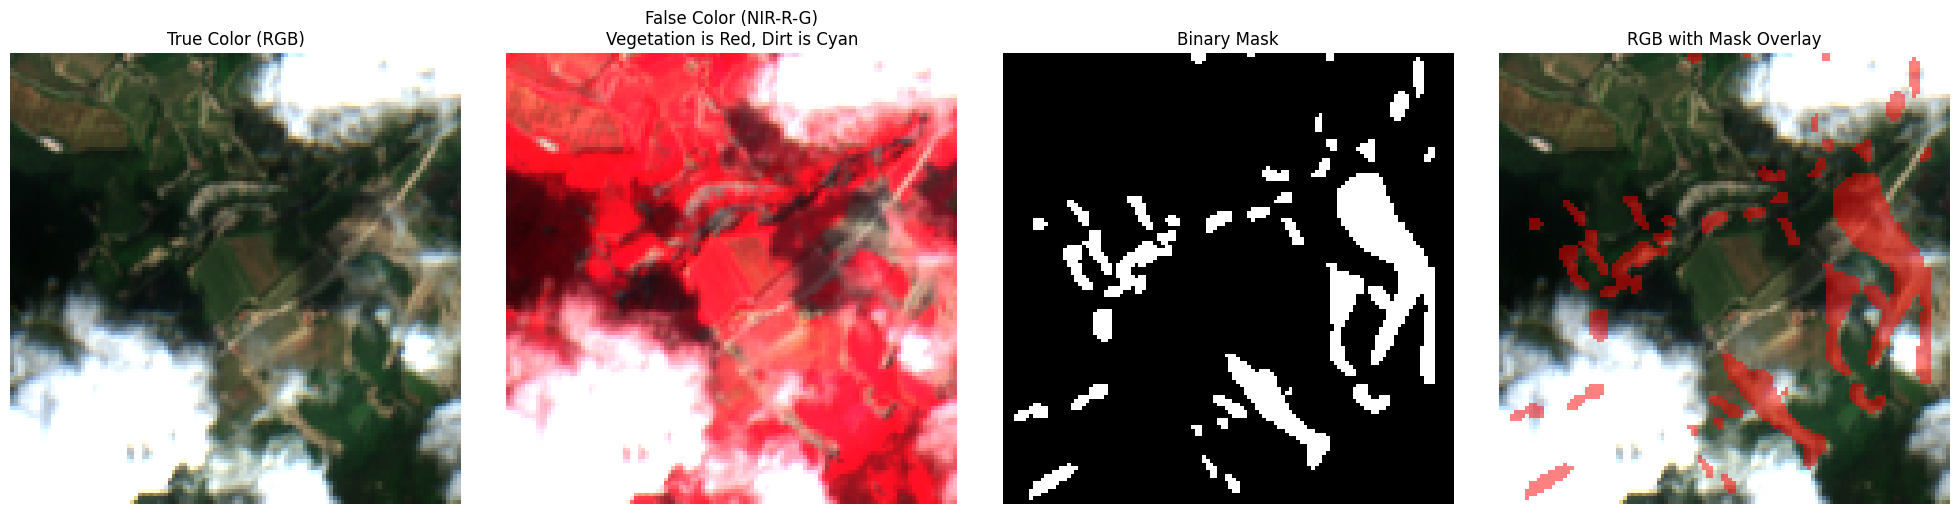

Loaded ROI 11366
Image shape: (12, 120, 120), Min: 0.0091, Max: 0.4868
Mask shape: (120, 120), Unique values: [0 1]


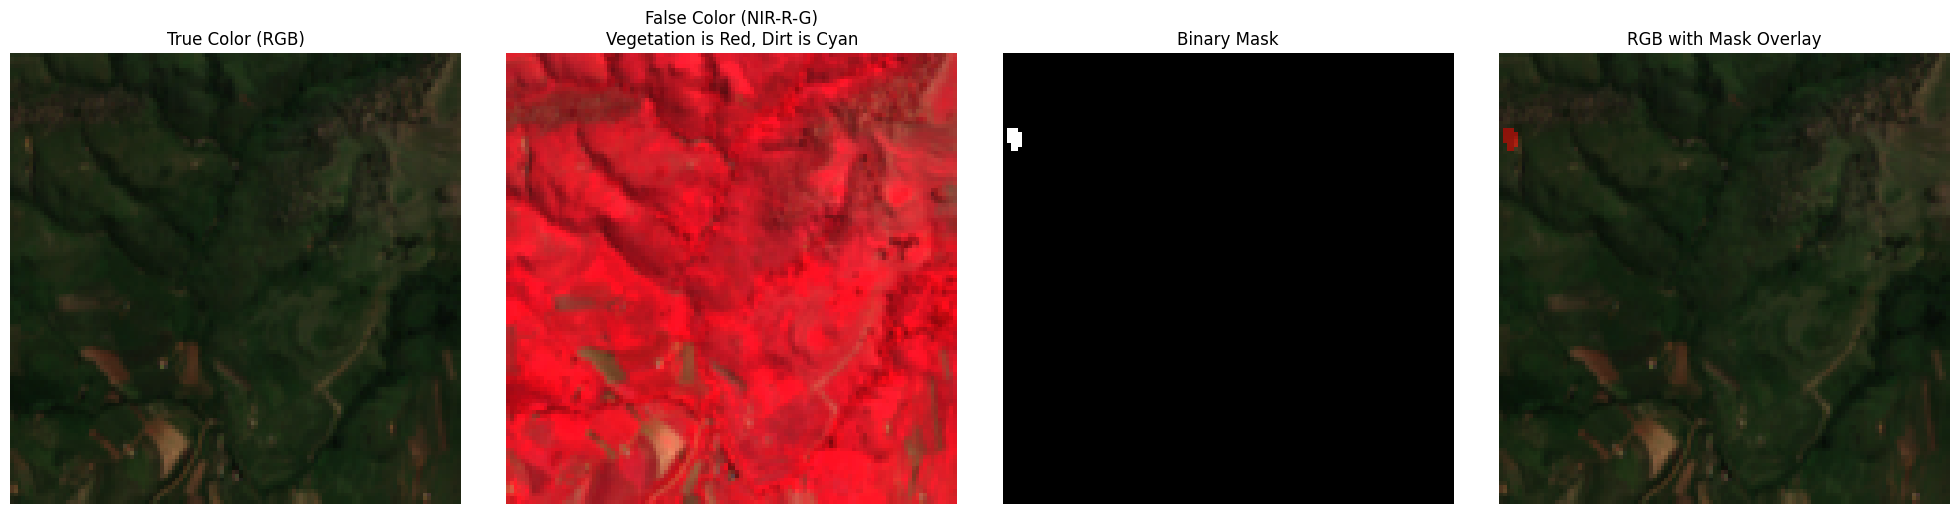

Loaded ROI 12925
Image shape: (12, 120, 120), Min: 0.0185, Max: 0.6084
Mask shape: (120, 120), Unique values: [0 1]


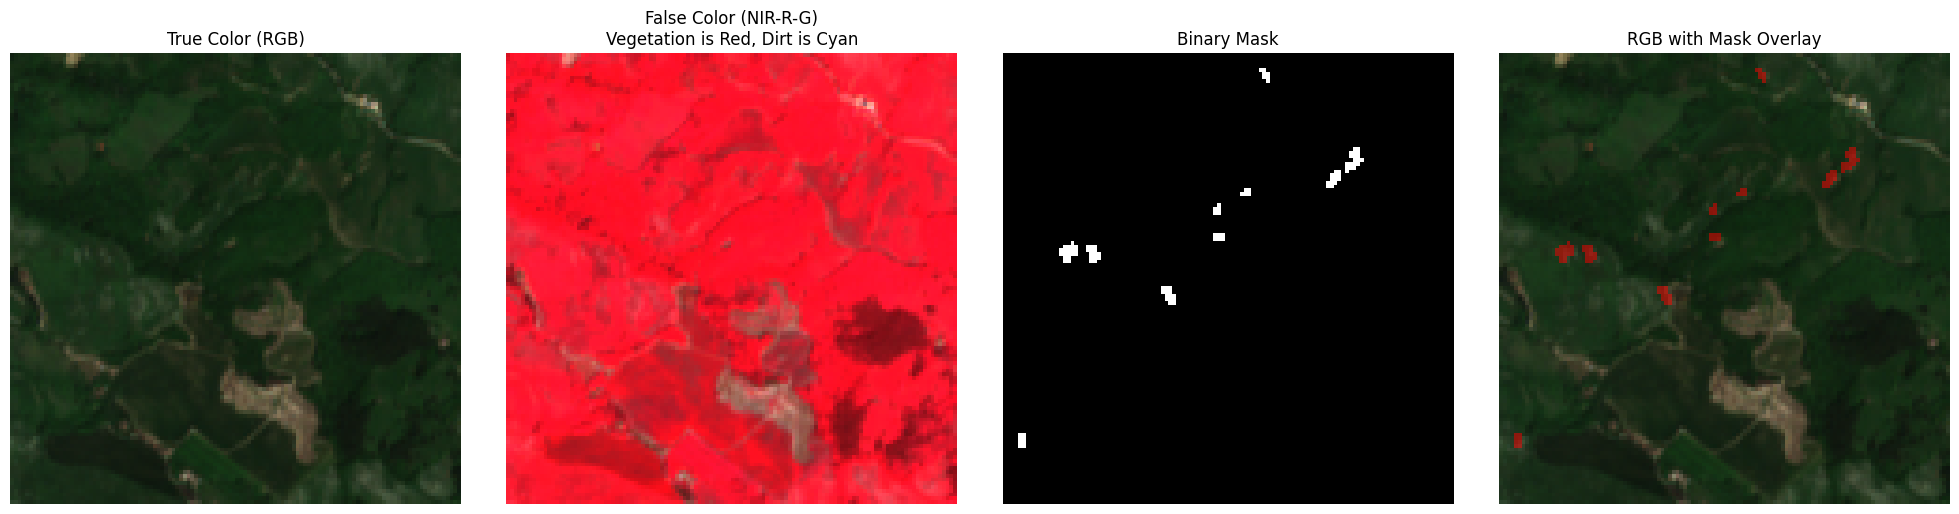

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

def validate_landslide(index, img_dir, mask_dir, prefix):
    # File paths
    img_path = os.path.join(img_dir, f"{prefix}_{index}_anomaly.npy")
    mask_path = os.path.join(mask_dir, f"{prefix}_{index}_anomaly_mask.npy")
    
    if not os.path.exists(img_path) or not os.path.exists(mask_path):
        print(f"Files for index {index} not found.")
        return

    # Load arrays
    img_array = np.load(img_path)   # Shape: (12, 120, 120)
    mask_array = np.load(mask_path) # Shape: (120, 120)
    
    print(f"Loaded ROI {index}")
    print(f"Image shape: {img_array.shape}, Min: {img_array.min():.4f}, Max: {img_array.max():.4f}")
    print(f"Mask shape: {mask_array.shape}, Unique values: {np.unique(mask_array)}")

    # Extract True Color (RGB: B4, B3, B2 -> Indices 3, 2, 1)
    rgb = img_array[[3, 2, 1], :, :].transpose(1, 2, 0)
    # Brighten the image slightly for better viewing (multiply by a factor, e.g., 2.5)
    rgb_bright = np.clip(rgb * 2.5, 0, 1)

    # Extract False Color Infrared (NIR, Red, Green: B8, B4, B3 -> Indices 7, 3, 2)
    # This makes vegetation appear bright red, and bare earth/mines appear cyan/grey
    fcc = img_array[[7, 3, 2], :, :].transpose(1, 2, 0)
    fcc_bright = np.clip(fcc * 2.5, 0, 1)

    # Setup the plot
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    # 1. True Color
    axes[0].imshow(rgb_bright)
    axes[0].set_title("True Color (RGB)")
    axes[0].axis("off")

    # 2. False Color
    axes[1].imshow(fcc_bright)
    axes[1].set_title("False Color (NIR-R-G)\nVegetation is Red, Dirt is Cyan")
    axes[1].axis("off")

    # 3. Mask Only
    axes[2].imshow(mask_array, cmap="gray")
    axes[2].set_title("Binary Mask")
    axes[2].axis("off")

    # 4. Mask Overlay on True Color
    axes[3].imshow(rgb_bright)
    # Overlay the mask using a red colormap and some transparency (alpha)
    # We mask out the '0' values so only the '1's (the mine) show up in red
    mask_overlay = np.ma.masked_where(mask_array == 0, mask_array)
    axes[3].imshow(mask_overlay, cmap="autumn", alpha=0.5)
    
    # Alternatively, draw a contour line instead of a solid fill:
    # axes[3].contour(mask_array, levels=[0.5], colors=['red'], linewidths=1.5)

    axes[3].set_title("RGB with Mask Overlay")
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()

# Test it on a few of the files you just generated
prefix = "landslide_patch"
img_dir = "./dataset/test/landslides/imgs"
mask_dir = "./dataset/test/landslides/masks/"
# for i in range(11):
#     validate_landslide(i, img_dir, mask_dir, prefix)
validate_landslide(108, img_dir, mask_dir, prefix)
validate_landslide(3181, img_dir, mask_dir, prefix)
validate_landslide(6735, img_dir, mask_dir, prefix)
validate_landslide(11366, img_dir, mask_dir, prefix)
validate_landslide(12925, img_dir, mask_dir, prefix)

## **WorldFloods**

In [2]:
save_dir_imgs = "./dataset/test/floods/imgs"
save_dir_masks = "./dataset/test/floods/masks"

In [4]:
import os
import json
import glob
import re
import pandas as pd
import geopandas as gpd
from shapely.geometry import box
import xarray as xr
import rasterio
import rioxarray
import numpy as np

import ee
import wxee
from dotenv import load_dotenv
load_dotenv()
ee.Authenticate()
ee.Initialize(project=os.getenv("EAI_PROJECT_ID"))

/usr/bin/xdg-open: 882: x-www-browser: not found
/usr/bin/xdg-open: 882: firefox: not found
/usr/bin/xdg-open: 882: iceweasel: not found
/usr/bin/xdg-open: 882: seamonkey: not found
/usr/bin/xdg-open: 882: mozilla: not found
/usr/bin/xdg-open: 882: epiphany: not found
/usr/bin/xdg-open: 882: konqueror: not found
/usr/bin/xdg-open: 882: chromium: not found
/usr/bin/xdg-open: 882: chromium-browser: not found
/usr/bin/xdg-open: 882: google-chrome: not found
/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening 'https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_c


Successfully saved authorization token.


In [12]:
# Locate all ground truth TIFFs
gt_files = glob.glob('./data/worldfloods_v1_0_sample/**/gt/*.tif', recursive=True)
print(f"{len(gt_files)} Ground Truth files found.")

for index, gt_path in enumerate(gt_files):
    print(f"\nProcessing ROI {index} - File: {os.path.basename(gt_path)}")

    try:
        basename = os.path.basename(gt_path)
        event_date = None

        # --------------- 1. Parse the Timestamp
        if basename.startswith("EMSR"):
            # It's from test/val, date is in the meta JSON
            # More robust path replacement
            json_path = gt_path.replace('/gt/', '/meta/').replace('\\gt\\', '\\meta\\').replace('.tif', '.json')
            
            if os.path.exists(json_path):
                with open(json_path, 'r') as f:
                    meta = json.load(f)
                    
                    # FIX: Use the actual key you found in the JSON
                    date_str = meta.get('satellite date', None) 
                    
                    if date_str:
                        # Convert ISO 8601 string (2018-05-17T15:36:15Z) to YYYY-MM-DD
                        event_date = pd.to_datetime(date_str).strftime('%Y-%m-%d')
            else:
                print(f"\tJSON not found at: {json_path}")
        else:
            # Train files: e.g., 01042016_Holmes_Creek_at_Vernon_FL.tif or ST1_20161014_WaterExtent...
            # A safer approach for WorldFloods train strings: look for any 8-digit sequence
            import re
            match = re.search(r'(\d{8})', basename)
            if match:
                date_str = match.group(1)
                try:
                    # Try MMDDYYYY first (e.g., 01042016)
                    event_date = pd.to_datetime(date_str, format='%m%d%Y').strftime('%Y-%m-%d')
                except ValueError:
                    try:
                        # Fallback to YYYYMMDD if the string was reversed (e.g., 20161014)
                        event_date = pd.to_datetime(date_str, format='%Y%m%d').strftime('%Y-%m-%d')
                    except ValueError:
                        pass

        start_date = event_date
        # Give GEE a tight 3-day window to find the image to avoid extreme temporal drift
        end_date = (pd.to_datetime(event_date) + pd.Timedelta(days=3)).strftime('%Y-%m-%d')

        # --------------- 2. Extract Spatial Bounds from Mask (FIXED)
        mask_da = rioxarray.open_rasterio(gt_path).squeeze()
        native_crs = mask_da.rio.crs.to_string()
        
        raw_mask = mask_da.values
        # WorldFloods assigns 2 to water/flood. We map 2 -> 1 (Anomaly)
        binary_mask = np.where(raw_mask == 2, 1, 0).astype(np.uint8)
        
        y_idx, x_idx = np.where(binary_mask == 1)
        if len(y_idx) == 0:
            print(f"\tSkipping ROI {index}: No flood (water) found in the mask.")
            continue
            
        # Find the center of the flood in local mask coordinates
        center_y, center_x = int(np.median(y_idx)), int(np.median(x_idx))
        
        # Convert local pixel coordinates to geospatial coordinates in native_crs
        x_coord, y_coord = mask_da.rio.transform() * (center_x + 0.5, center_y + 0.5) 
        
        # Create Point in native_crs
        pt = gpd.GeoSeries([gpd.points_from_xy([x_coord], [y_coord])[0]], crs=native_crs)
        
        # FIX: Explicitly convert to metric projection (EPSG:3857) BEFORE buffering by 600 meters!
        pt_metric = pt.to_crs(epsg=3857)
        roi_geom_3857 = pt_metric.buffer(600).envelope.iloc[0]  # Exact 1200m x 1200m square box
        
        # Convert back to EPSG:4326 for Earth Engine
        roi_geom_4326 = gpd.GeoSeries([roi_geom_3857], crs="EPSG:3857").to_crs(epsg=4326).iloc[0]
        
        ee_minx, ee_miny, ee_maxx, ee_maxy = roi_geom_4326.bounds
        roi = ee.Geometry.Rectangle([ee_minx, ee_miny, ee_maxx, ee_maxy])

        # --------------- 3. Fetch Image from Earth Engine (FIXED)
        s2_collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                         .filterDate(start_date, end_date)
                         .filterBounds(roi)
                         .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40)))
        
        if s2_collection.size().getInfo() == 0:
            print(f"\tImage not found in Earth Engine window.")
            continue

        s2_image = (s2_collection.mosaic()
                    .select(BANDS_TO_USE)
                    .set('system:time_start', ee.Date(start_date).millis()))
        
        # Download using EPSG:3857 so scale=10 corresponds to exactly 10 meters per pixel (120x120 pixels)
        ds_gee = s2_image.wx.to_xarray(region=roi, scale=10, crs="EPSG:3857", progress=False)

        # --------------- 4. Convert GEE Data to Numpy
        data = np.stack([np.squeeze(ds_gee[b].values) for b in BANDS_TO_USE], axis=0)
        data_float = data.astype(np.float32) / 10000.0
        img_array = np.nan_to_num(data_float)

        # --------------- 5. Align and Extract Mask (FIXED)
        ds_gee = ds_gee.rio.write_crs("EPSG:3857")
        
        # Reproject the ground truth mask to match the 120x120 EPSG:3857 GEE patch
        matched_mask_da = mask_da.rio.reproject_match(ds_gee, resampling=rasterio.enums.Resampling.nearest)
        
        raw_mask_matched = matched_mask_da.values
        mask_array = np.where(raw_mask_matched == 2, 1, 0).astype(np.uint8)

        # --------------- 6. Force 120x120 Crop (Simplified)
        # We no longer need to search for the center because we already centered the GEE download on the flood.
        # We just ensure it's exactly 120x120 to fix any 121x121 rounding errors from GEE.
        img_array = img_array[:, :TARGET_SIZE, :TARGET_SIZE]
        mask_array = mask_array[:TARGET_SIZE, :TARGET_SIZE]

        if img_array.max() == 0 or img_array.shape[1] < TARGET_SIZE or img_array.shape[2] < TARGET_SIZE:
            print(f"\tSkipping ROI {index}: Image is empty or too small.")
            continue

        label = "anomaly"
        np.save(os.path.join(save_dir_imgs, f"flood_patch_{index}_{label}.npy"), img_array)
        np.save(os.path.join(save_dir_masks, f"flood_patch_{index}_{label}_mask.npy"), mask_array)

        print(f"\tSaved ROI {index} - Image: {img_array.shape}, Mask: {mask_array.shape}")

    except Exception as e:
        print(f"\tSkipping {index}, error: {e}")
        continue

37 Ground Truth files found.

Processing ROI 0 - File: EMSR9284_01YLITORNIONORTHERN_DEL_MONIT01_v1_observed_event_a.tif
	Saved ROI 0 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 1 - File: EMSR347_06MWANZA_DEL_v1_observed_event_a.tif
	Saved ROI 1 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 2 - File: EMSR333_01RATTALORO_DEL_MONIT01_v1_observed_event_a.tif
	Saved ROI 2 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 3 - File: EMSR333_13TORRECOLONNASPERONE_DEL_MONIT01_v2_observed_event_a.tif
	Saved ROI 3 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 4 - File: EMSR347_07ZOMBA_DEL_MONIT01_v1_observed_event_a.tif
	Saved ROI 4 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 5 - File: EMSR286_08ITUANGONORTH_DEL_MONIT02_v1_observed_event_a.tif
	Image not found in Earth Engine window.

Processing ROI 6 - File: EMSR333_02PORTOPALO_DEL_MONIT01_v1_observed_event_a.tif
	Saved ROI 6 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 7 -

### Validating


Loaded ROI 0
Image shape: (12, 120, 120), Min: 0.0002, Max: 0.1965
Mask shape: (120, 120), Unique values: [0 1]


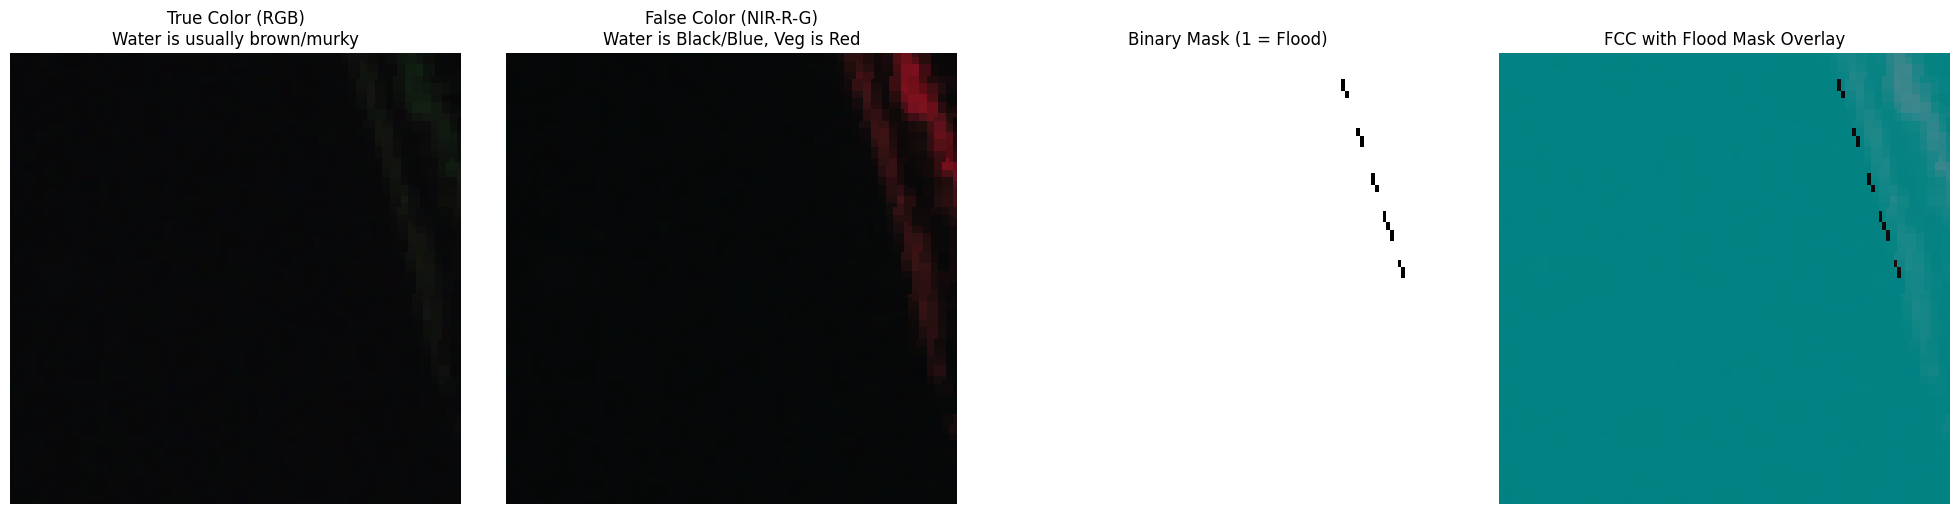


Loaded ROI 10
Image shape: (12, 120, 120), Min: 0.0056, Max: 0.5118
Mask shape: (120, 120), Unique values: [0 1]


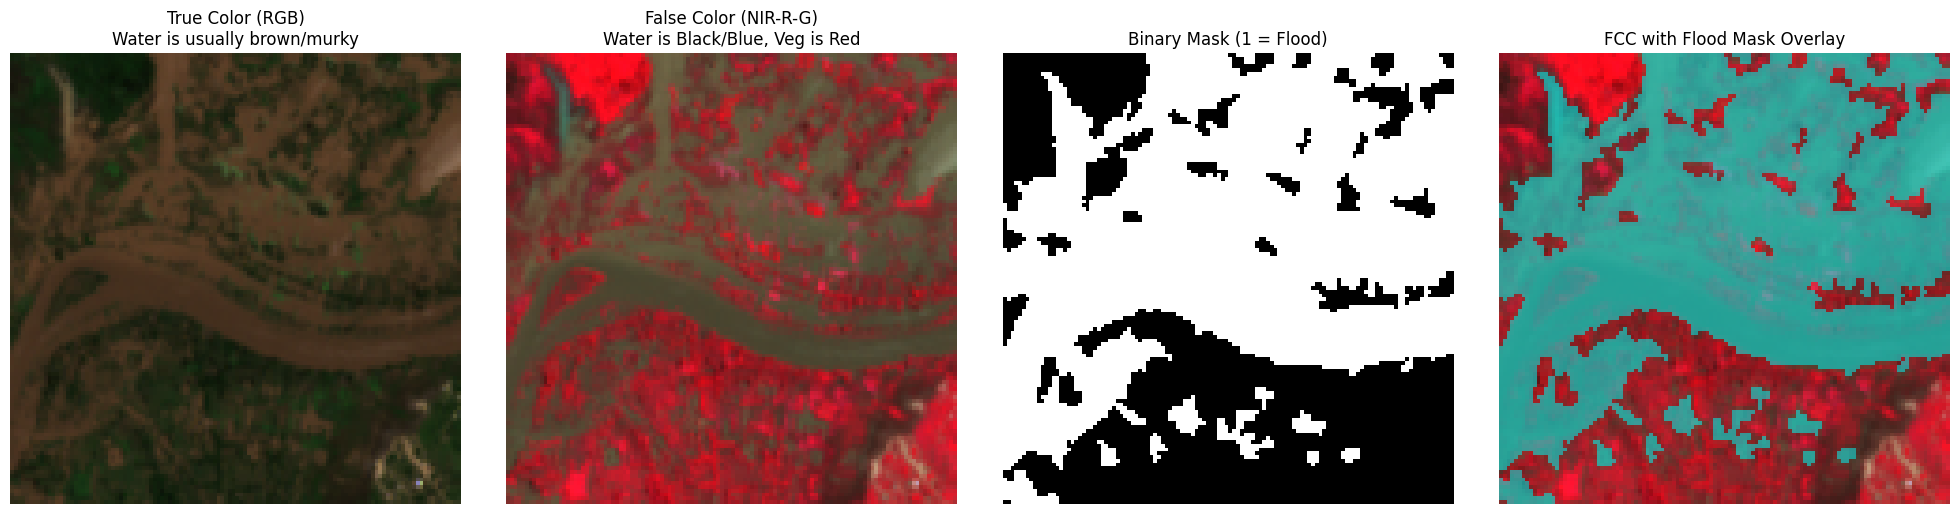


Loaded ROI 12
Image shape: (12, 120, 120), Min: 0.0120, Max: 0.3253
Mask shape: (120, 120), Unique values: [0]


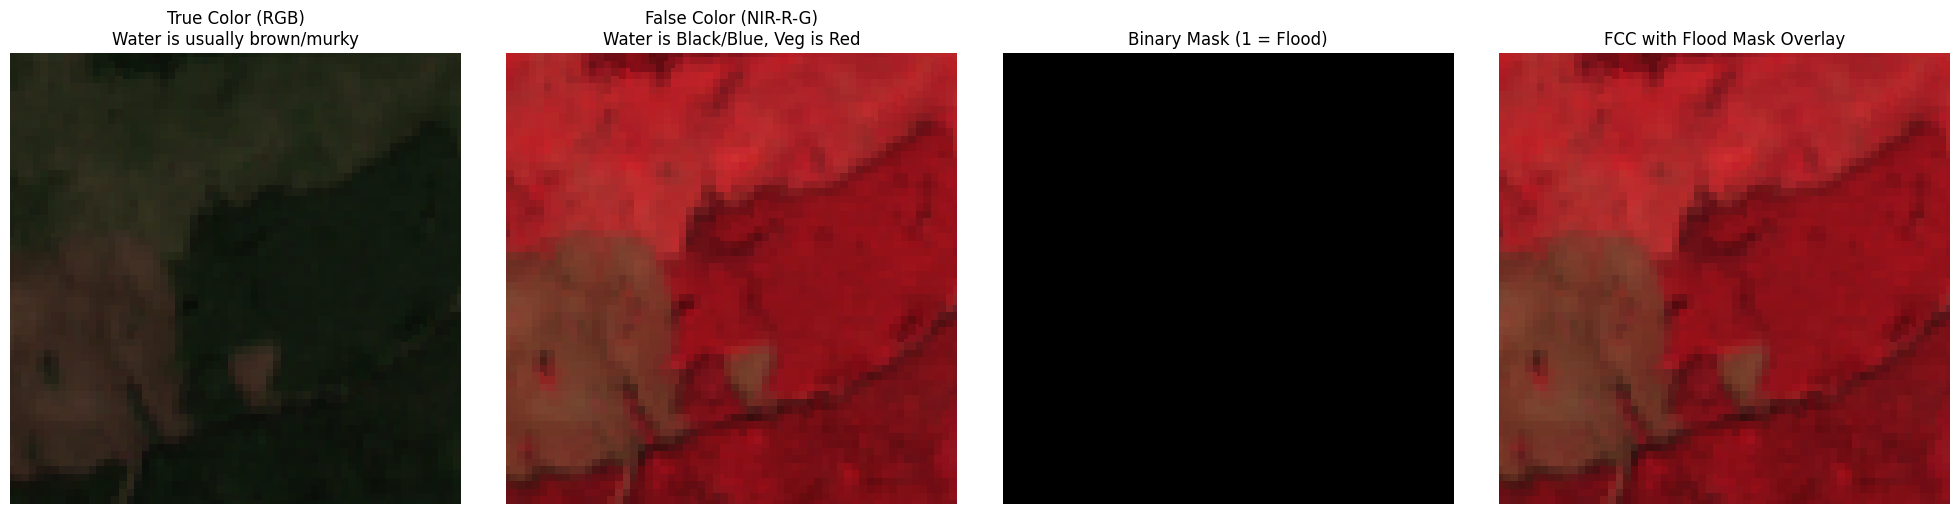


Loaded ROI 14
Image shape: (12, 120, 120), Min: 0.0001, Max: 0.4755
Mask shape: (120, 120), Unique values: [0 1]


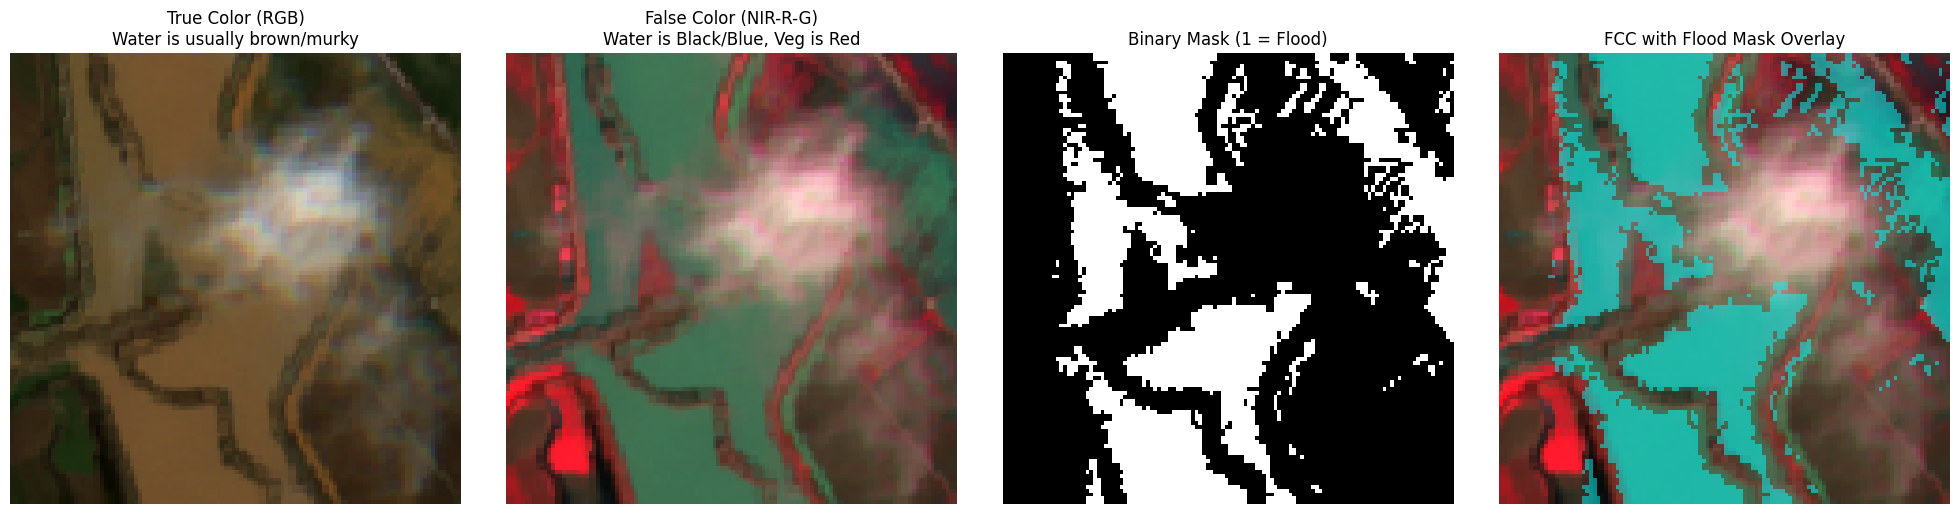


Loaded ROI 15
Image shape: (12, 120, 120), Min: 0.0065, Max: 0.4351
Mask shape: (120, 120), Unique values: [0 1]


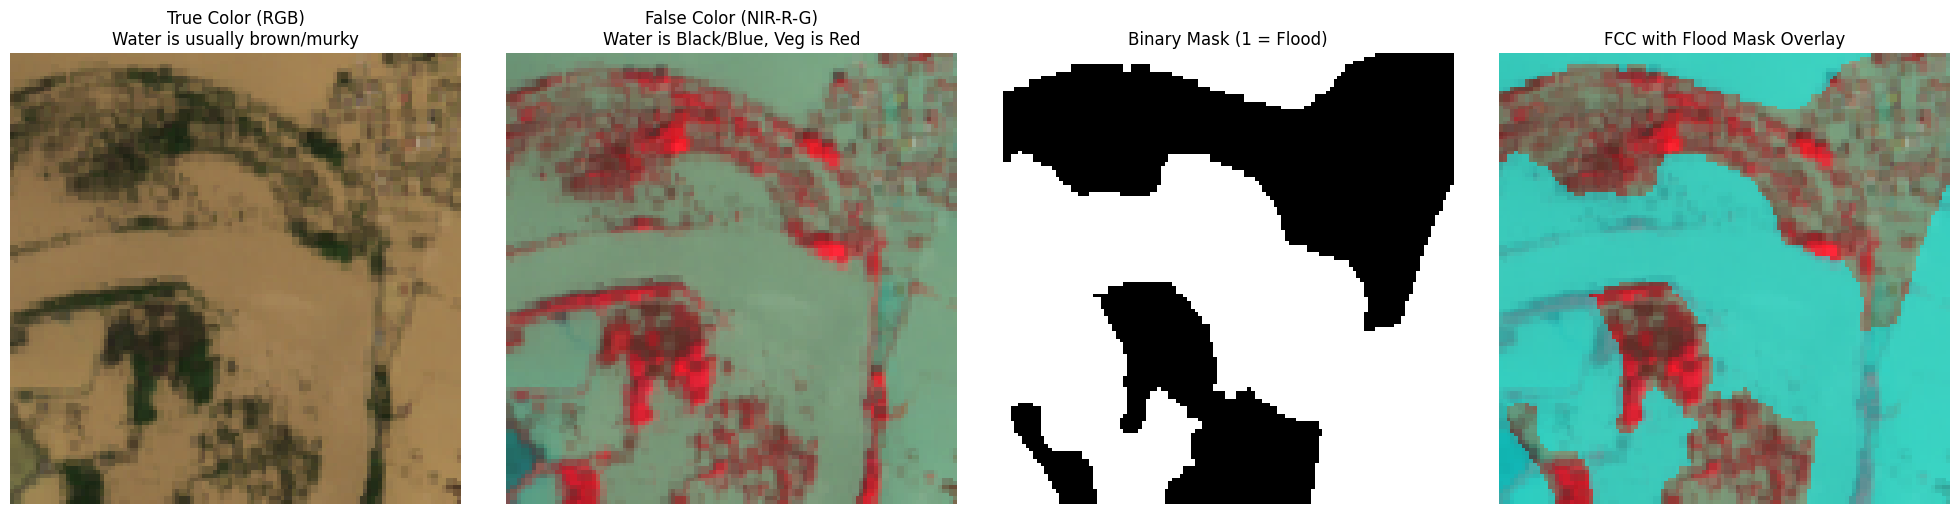


Loaded ROI 1
Image shape: (12, 120, 120), Min: 0.0001, Max: 0.6400
Mask shape: (120, 120), Unique values: [0]


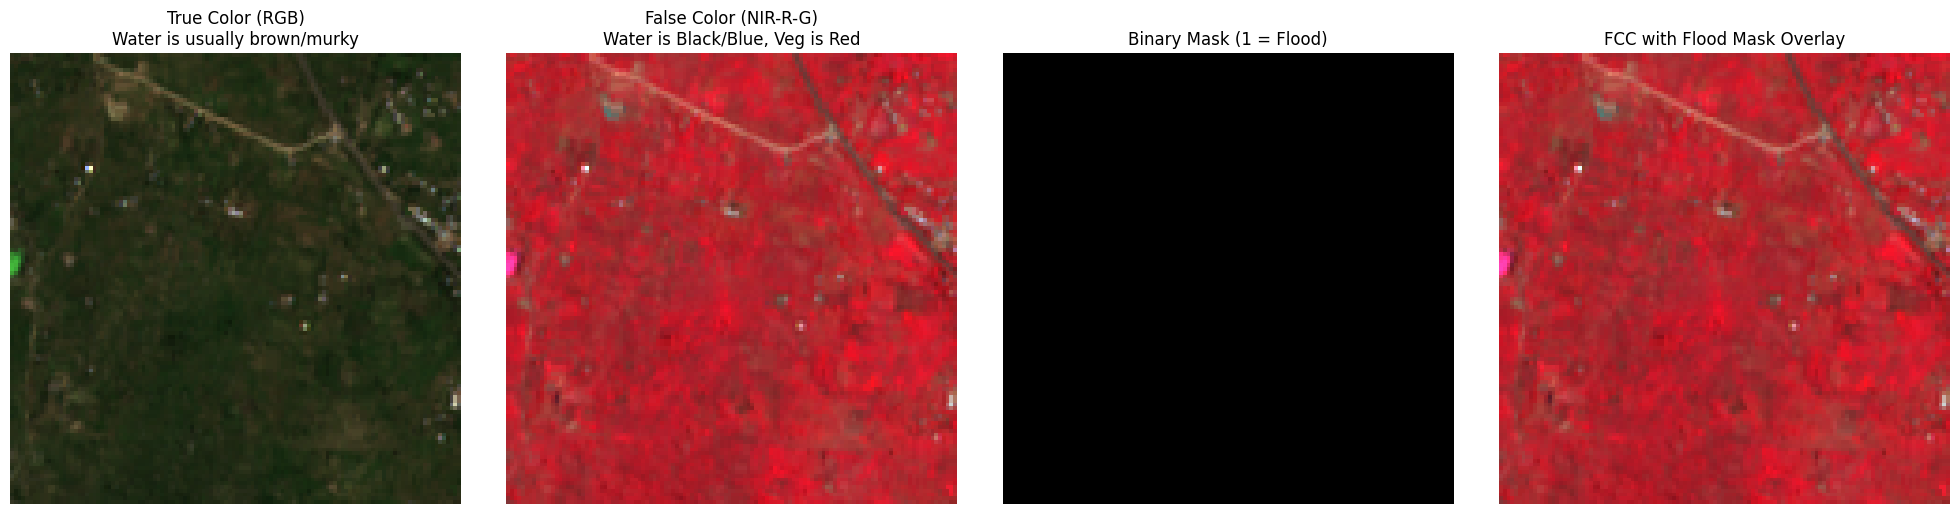


Loaded ROI 2
Image shape: (12, 120, 120), Min: 0.0165, Max: 0.6284
Mask shape: (120, 120), Unique values: [0 1]


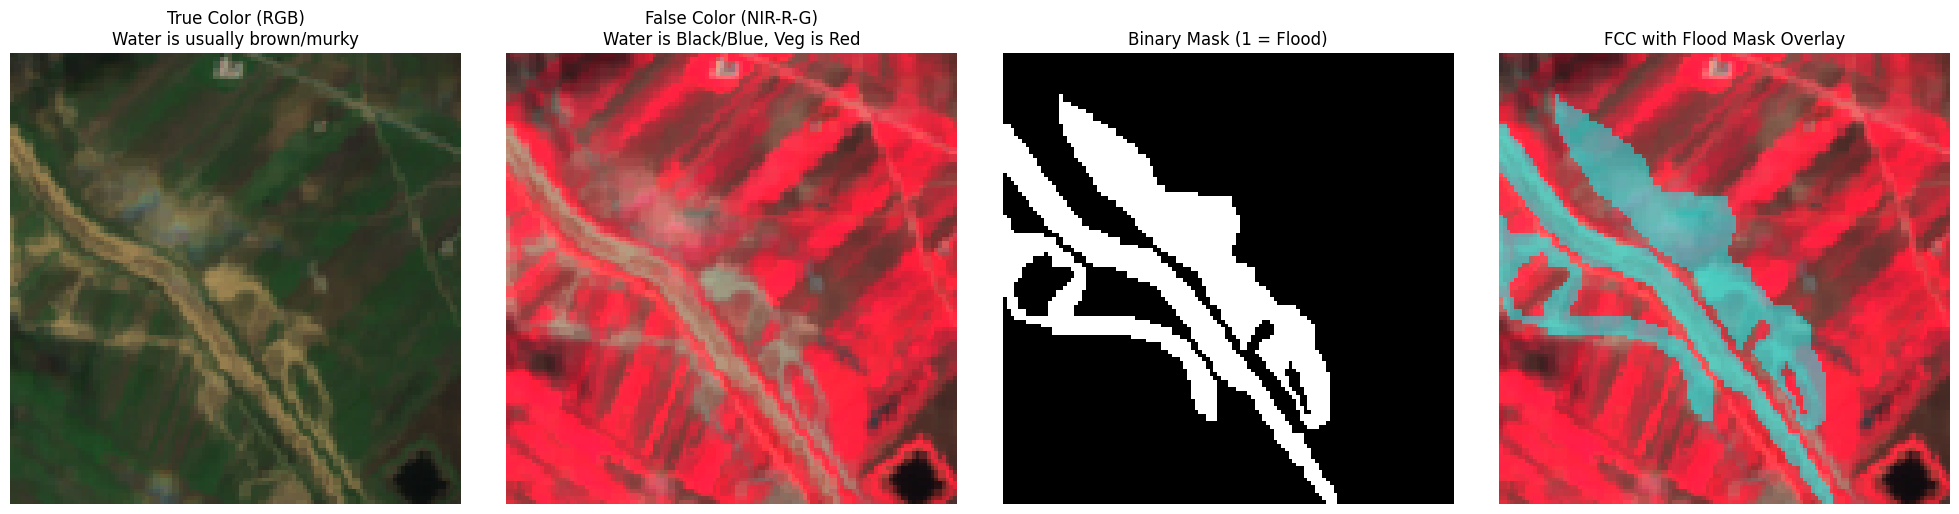


Loaded ROI 3
Image shape: (12, 120, 120), Min: 0.0133, Max: 0.6544
Mask shape: (120, 120), Unique values: [0 1]


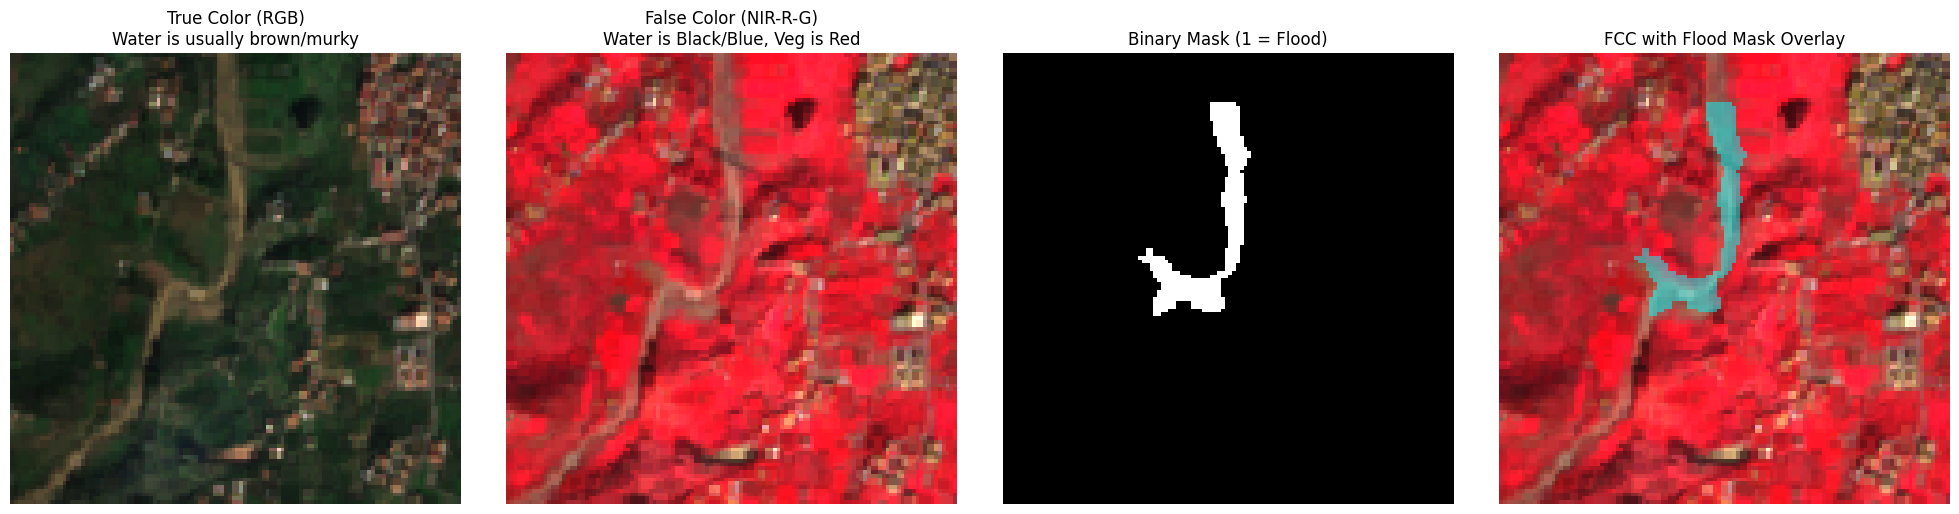


Loaded ROI 4
Image shape: (12, 120, 120), Min: 0.0036, Max: 0.1224
Mask shape: (120, 120), Unique values: [1]


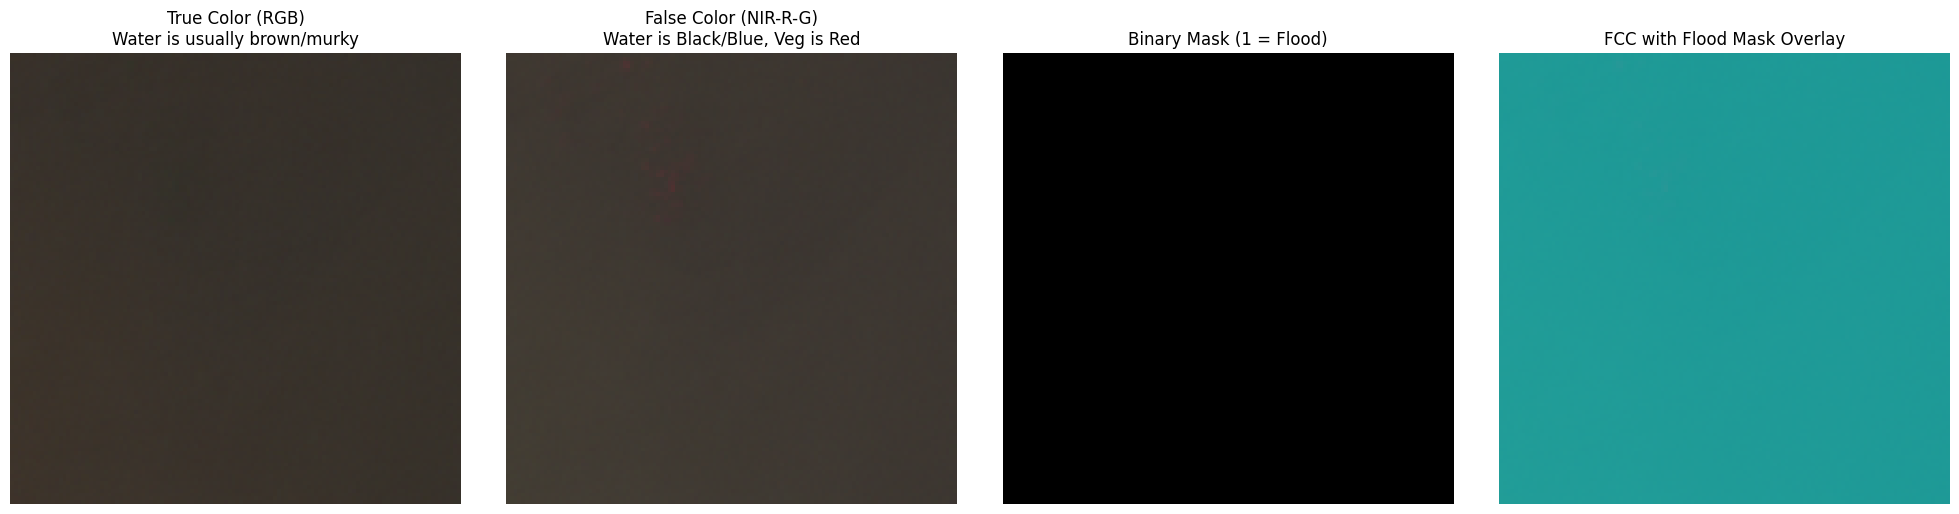


Loaded ROI 6
Image shape: (12, 120, 120), Min: 0.0038, Max: 0.5824
Mask shape: (120, 120), Unique values: [0 1]


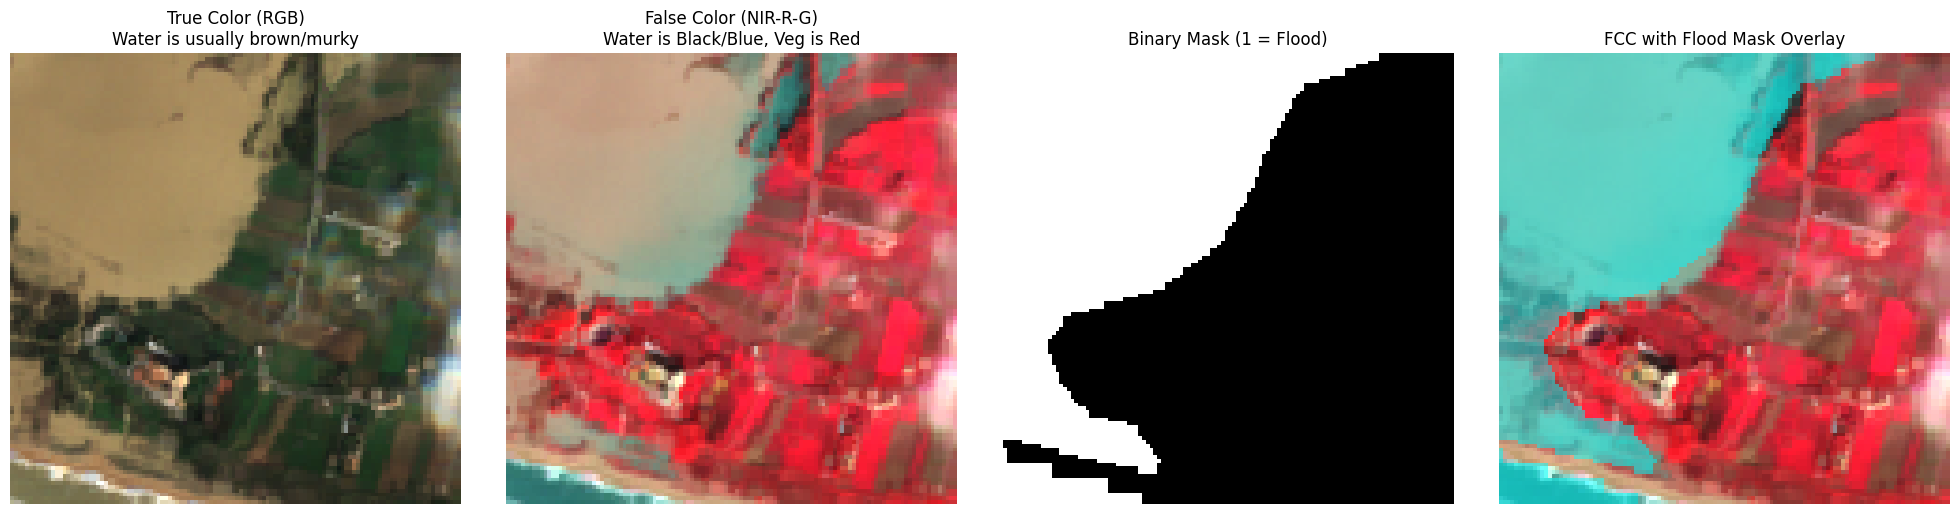


Loaded ROI 9
Image shape: (12, 120, 120), Min: 0.0028, Max: 0.3694
Mask shape: (120, 120), Unique values: [0 1]


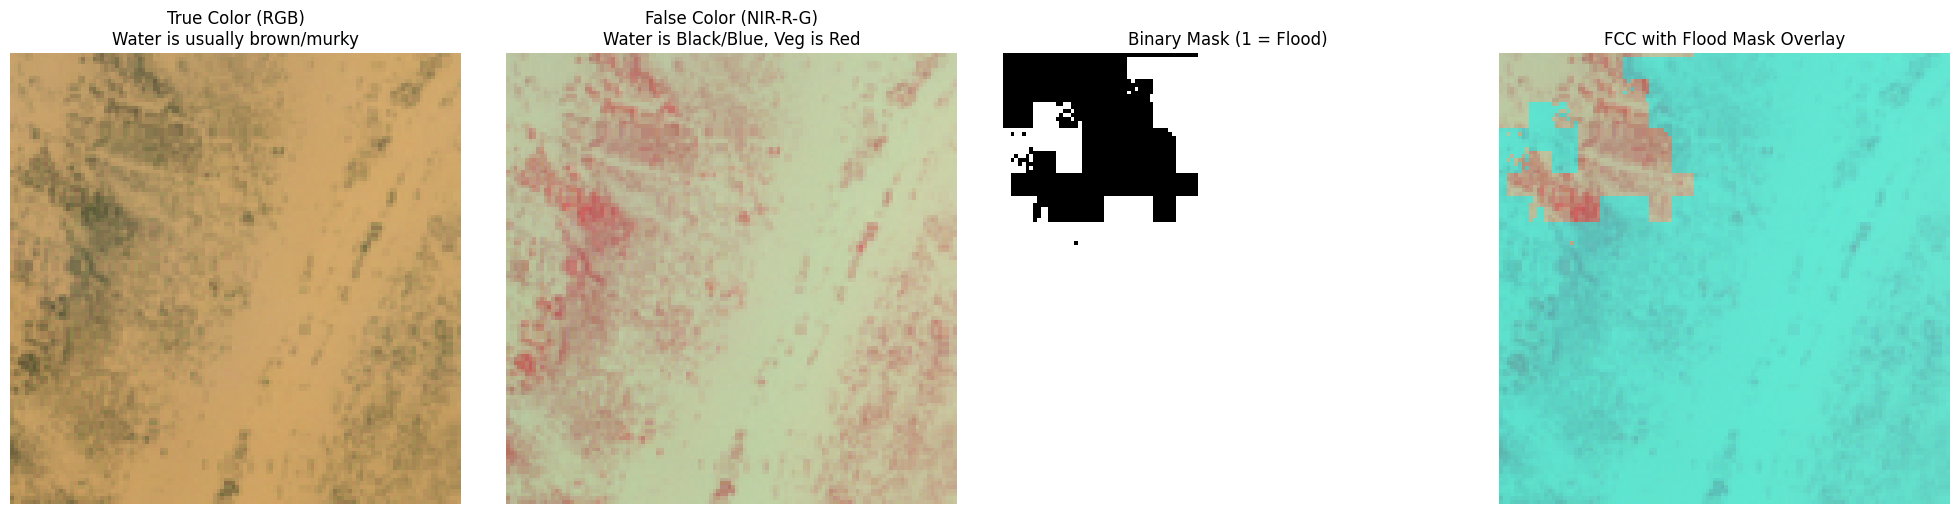

In [15]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

def validate_flood(index, img_dir, mask_dir, prefix):
    # File paths
    img_path = os.path.join(img_dir, f"{prefix}_{index}_anomaly.npy")
    mask_path = os.path.join(mask_dir, f"{prefix}_{index}_anomaly_mask.npy")
    
    if not os.path.exists(img_path) or not os.path.exists(mask_path):
        print(f"Files for index {index} not found. Skipping...")
        return

    # Load arrays
    img_array = np.load(img_path)   # Shape: (12, 120, 120)
    mask_array = np.load(mask_path) # Shape: (120, 120)
    
    print(f"\nLoaded ROI {index}")
    print(f"Image shape: {img_array.shape}, Min: {img_array.min():.4f}, Max: {img_array.max():.4f}")
    print(f"Mask shape: {mask_array.shape}, Unique values: {np.unique(mask_array)}")

    # Extract True Color (RGB: B4, B3, B2 -> Indices 3, 2, 1)
    rgb = img_array[[3, 2, 1], :, :].transpose(1, 2, 0)
    rgb_bright = np.clip(rgb * 2.5, 0, 1)

    # Extract False Color Infrared (NIR, Red, Green: B8, B4, B3 -> Indices 7, 3, 2)
    # Water absorbs NIR light, so floods will appear extremely dark (black/dark blue)
    # while surrounding healthy vegetation will appear bright red.
    fcc = img_array[[7, 3, 2], :, :].transpose(1, 2, 0)
    fcc_bright = np.clip(fcc * 2.5, 0, 1)

    # Setup the plot
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    # 1. True Color
    axes[0].imshow(rgb_bright)
    axes[0].set_title("True Color (RGB)\nWater is usually brown/murky")
    axes[0].axis("off")

    # 2. False Color
    axes[1].imshow(fcc_bright)
    axes[1].set_title("False Color (NIR-R-G)\nWater is Black/Blue, Veg is Red")
    axes[1].axis("off")

    # 3. Mask Only
    axes[2].imshow(mask_array, cmap="gray")
    axes[2].set_title("Binary Mask (1 = Flood)")
    axes[2].axis("off")

    # 4. Mask Overlay on False Color (Easier to see flood boundaries)
    axes[3].imshow(fcc_bright)
    mask_overlay = np.ma.masked_where(mask_array == 0, mask_array)
    # Use a high-contrast cyan overlay to stand out against the dark water
    axes[3].imshow(mask_overlay, cmap="cool", alpha=0.5)
    
    axes[3].set_title("FCC with Flood Mask Overlay")
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()

# Test it on the first 10 existing files
prefix = "flood_patch"
img_dir = "./dataset/test/floods/imgs"
mask_dir = "./dataset/test/floods/masks"

# Dynamically find the files that actually exist
existing_files = sorted(glob.glob(os.path.join(img_dir, f"{prefix}_*_anomaly.npy")))

for file_path in existing_files:
    # Extract the index number from the filename (e.g., 'flood_patch_4_anomaly.npy' -> '4')
    filename = os.path.basename(file_path)
    index = filename.split('_')[2]
    validate_flood(index, img_dir, mask_dir, prefix)

# **TRAIN**

## Ben-ge-8k
Preprocessing

In [2]:
import os
import glob
import numpy as np
import rasterio
from rasterio.enums import Resampling

In [3]:
INPUT_DIR = "./data/ben-ge-8k/sentinel-2"
OUTPUT_DIR = "./dataset/train/ben-ge-8k"

# Ensure output directory exists
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Define ben-ge-8k band names in the same order used for GEE (for the test set).
BANDS_TO_EXTRACT = [
    'B01', 'B02', 'B03', 'B04', 'B05', 'B06', 
    'B07', 'B08', 'B8A', 'B09', 'B11', 'B12'
]


# ---------- Processing
# Find all the patch directories in the dataset
patch_dirs = glob.glob(os.path.join(INPUT_DIR, "S2A_MSIL2A_*"))
print(f"Found {len(patch_dirs)} patches to process.")

for index, patch_path in enumerate(patch_dirs):
    patch_name = os.path.basename(patch_path)
    
    try:
        band_arrays = []
        missing_band = False
        
        # Loop through the exact band order needed
        for band_name in BANDS_TO_EXTRACT:
            # Construct the expected filename for this specific band
            band_filename = f"{patch_name}_{band_name}.tif"
            band_filepath = os.path.join(patch_path, band_filename)
            
            if not os.path.exists(band_filepath):
                print(f"Missing {band_name} in {patch_name}. Skipping patch.")
                missing_band = True
                break
                
            # Read and automatically resize using rasterio
            with rasterio.open(band_filepath) as src:
                # out_shape forces the array to 120x120. 
                # Resampling.bilinear interpolates the 20m and 60m bands smoothly.
                band_data = src.read(
                    1, 
                    out_shape=(TARGET_SIZE, TARGET_SIZE), 
                    resampling=Resampling.bilinear
                )
                band_arrays.append(band_data)
        
        if missing_band:
            continue
            
        # Stack into shape (12, 120, 120)
        img_array_raw = np.stack(band_arrays, axis=0)
        
        # Scale
        img_array_float = img_array_raw.astype(np.float32) / 10000.0
        
        # Clean NaNs
        img_array_clean = np.nan_to_num(img_array_float)
        
        # Save
        save_path = os.path.join(OUTPUT_DIR, f"{patch_name}.npy")
        np.save(save_path, img_array_clean)
        
        if index % 500 == 0:
            print(f"Processed {index}/{len(patch_dirs)} patches...")

    except Exception as e:
        print(f"Error processing {patch_name}: {e}")

print("ben-ge-8k preprocessing complete")

Found 3617 patches to process.
Processed 0/3617 patches...
Processed 500/3617 patches...
Processed 1000/3617 patches...
Processed 1500/3617 patches...
Processed 2000/3617 patches...
Processed 2500/3617 patches...
Processed 3000/3617 patches...
Processed 3500/3617 patches...
ben-ge-8k preprocessing complete


## Data from every biome considered

### Global ML

In [2]:
save_dir_imgs = "./dataset/train/mines/"

In [4]:
import os
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
import rioxarray
import fiona

import ee
import wxee
from dotenv import load_dotenv
load_dotenv()
ee.Authenticate()
ee.Initialize(project=os.getenv("EAI_PROJECT_ID"))

import numpy as np

import random
from shapely.affinity import translate  # for the spatial shift

In [5]:
gpkg_path = './data/Global_ML/mining_area_data.gpkg'
print(f"layers:\n\t{fiona.listlayers(gpkg_path)}")

# Load the tiles table (contains the s2_tile_name)
gdf_tiles = gpd.read_file(gpkg_path, layer='tiles')
print(f"\ntiles table:\t{gdf_tiles.columns}")

# Load the validated polygons (or whichever polygon layer you intend to use)
gdf_polygons = gpd.read_file(gpkg_path, layer='test_polygons_validated') 
# Split the giant MULTIPOLYGON into individual mine polygons
gdf_polygons = gdf_polygons.explode(index_parts=False).reset_index(drop=True)
print(f"\npolygons table:\t{gdf_polygons.columns}")

# Merge them based on tile_id
gdf = gdf_polygons.merge(gdf_tiles[['tile_id', 's2_tile_id']], on='tile_id', how='left')

# apply projections
gdf_metric = gdf.to_crs(epsg=3857) 
gdf_shifted_metric = gdf_metric.copy()


def apply_random_shift(geom):
    angle = random.uniform(0, 2 * np.pi)       # Random direction
    distance = random.uniform(2000, 5000)      # Random distance between 2km and 5km
    dx = distance * np.cos(angle)
    dy = distance * np.sin(angle)
    return translate(geom, xoff=dx, yoff=dy)

gdf_shifted_metric['geometry'] = gdf_shifted_metric.geometry.centroid.apply(apply_random_shift)  # Apply shift to the centroid
gdf_shifted_metric['geometry'] = gdf_shifted_metric.geometry.buffer(600).envelope  # buffer of 600 meters around the centroid of each polygon, cap the bounding box (makes it a perfect square)
gdf_buffered = gdf_shifted_metric.to_crs(epsg=4326)

print(f"\nMerged & Shifted table:\t{gdf_buffered.columns}")

layers:
	['maus_polygons', 'tang_polygons', 'maus_bboxes', 'tang_bboxes', 'preferred_polygons', 'preferred_bboxes', 'tiles', 'test_polygons_validated']

tiles table:	Index(['tile_id', 's2_tile_id', 'source_dataset', 'preferred_dataset',
       'minetype1', 'minetype2', 'comment', 'timestamp', 'split', 'geometry'],
      dtype='object')

polygons table:	Index(['tile_id', 'geometry'], dtype='object')

Merged & Shifted table:	Index(['tile_id', 'geometry', 's2_tile_id'], dtype='object')


In [7]:
n_rois = len(gdf_buffered)

# download the mines multispectral images
for index, row in gdf_buffered.iterrows():
    # ------------------------------------------------- CANCELLARE
    expected_filepath = os.path.join(save_dir_imgs, f"mines_biome_{index}.npy")
    if os.path.exists(expected_filepath):
        print(f"Skipping ROI {index}/{n_rois-1} - Already downloaded.")
        continue
    # -------------------------------------------------


    minx, miny, maxx, maxy = row.geometry.bounds    # bounding box from the polygon geometry
    roi = ee.Geometry.Rectangle([minx, miny, maxx, maxy])
    
    s2_tile_id = row['s2_tile_id']
    print(f"\nProcessing ROI {index}/{n_rois-1} - Tile: {s2_tile_id}")

    try:
        # --------------- fetch the image
        parts = s2_tile_id.split('_')
        date_str = parts[2][:8]
        start_date = f"{date_str[:4]}-{date_str[4:6]}-{date_str[6:]}"
        end_date = (pd.to_datetime(start_date) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
        mgrs_tile = parts[4][1:]
        # print(f"\nProcessing ROI {index} - Tile: {s2_tile_id}\n\tDate: {start_date}, MGRS: {mgrs_tile}")
        
        s2_collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                         .filterDate(start_date, end_date)
                         .filter(ee.Filter.eq('MGRS_TILE', mgrs_tile)))
        
        if s2_collection.size().getInfo() == 0:
            print(f"Image {s2_tile_id} not found in Earth Engine.")
            continue

        s2_image = s2_collection.first().select(BANDS_TO_USE)
        
        # --------------- download the images (from the roi at the specified time interval) into the RAM
        ds = s2_image.wx.to_xarray(region=roi, scale=10, crs="EPSG:3857", progress=False)

        # --------------- convert data to numpy
        # stack bands
        data = np.stack([np.squeeze(ds[b].values) for b in BANDS_TO_USE], axis=0)    # (Channels, H, W)
        # Clean up any missing edge pixels and scale the Sentinel-2 L2A values
        data_float = data.astype(np.float32) / 10000.0
        img_array = np.nan_to_num(data_float)

        # --------------- force 120x120 shape to guarantee compatibility with ben-ge-8k
        img_array = img_array[:, :TARGET_SIZE, :TARGET_SIZE]

        if img_array.max() == 0:
            print(f"Skipping ROI {index}: Image is empty (edge of swath).")
            continue
        if img_array.shape[1] < TARGET_SIZE or img_array.shape[2] < TARGET_SIZE:
            print(f"Skipping ROI {index}: Image is smaller than {TARGET_SIZE}x{TARGET_SIZE}.")
            continue

        np.save(os.path.join(save_dir_imgs, f"mines_biome_{index}.npy"), img_array)

        print(f"\tSaved ROI {index} - Image: {img_array.shape}")

    except Exception as e:
        print(f"Skipping ROI {index}, error: {e}")
        continue

Skipping ROI 0/1196 - Already downloaded.
Skipping ROI 1/1196 - Already downloaded.
Skipping ROI 2/1196 - Already downloaded.
Skipping ROI 3/1196 - Already downloaded.
Skipping ROI 4/1196 - Already downloaded.
Skipping ROI 5/1196 - Already downloaded.
Skipping ROI 6/1196 - Already downloaded.
Skipping ROI 7/1196 - Already downloaded.
Skipping ROI 8/1196 - Already downloaded.
Skipping ROI 9/1196 - Already downloaded.
Skipping ROI 10/1196 - Already downloaded.
Skipping ROI 11/1196 - Already downloaded.
Skipping ROI 12/1196 - Already downloaded.
Skipping ROI 13/1196 - Already downloaded.
Skipping ROI 14/1196 - Already downloaded.
Skipping ROI 15/1196 - Already downloaded.
Skipping ROI 16/1196 - Already downloaded.
Skipping ROI 17/1196 - Already downloaded.
Skipping ROI 18/1196 - Already downloaded.
Skipping ROI 19/1196 - Already downloaded.
Skipping ROI 20/1196 - Already downloaded.
Skipping ROI 21/1196 - Already downloaded.
Skipping ROI 22/1196 - Already downloaded.
Skipping ROI 23/1196 